# SPY Options Backtesting
### Options Strategy Recommendation and Optimisation System · Notebook 08

Evaluate a **selective chronological trading policy** using SPY option quotes from 2020–2022. The original GA supplies shadow recommendations; past trend and settled strategy evidence determine whether to trade.

**Generate shadow recommendations → check past trend and settled evidence → enter next session → estimate expiry payoff**

| Start here | What to do |
|---|---|
| Data | Place `spy_2020_2022.csv` in `../backtest_dataset/` relative to the notebook's working directory. |
| Dependencies | Use the packages imported in Section 1.1; engine regeneration also requires `networkx` and `rdflib`. |
| Configuration | Review the paths, costs and worker count in Section 1. |
| Run | Restart the kernel, then select **Run All**. Each run builds a temporary daily cache. |
| Results | Read the scorecard, charts, trade log and skipped-trade summary in Sections 6–7. |

[1. Setup](#setup) · [2. Data audit](#data) · [3. Recommendation engine](#engine) · [4. Historical adapter](#adapter) · [5. Backtest](#backtest) · [6. Results](#results) · [7. Validation](#validation) · [8. Assumptions](#assumptions)

> **Interpretation:** these are simulated trades using historical quotes. The default expiry price is the dataset's underlying snapshot, not a separately verified official close. The original baseline evaluates both outlooks separately; the revised policy selects at most one outlook per decision date. All reported comparisons are retrospective.

**Code layout:** settings are in Section 1; data and reusable helpers in Sections 2–4; execution in Section 5; reports in Section 6; checks in Section 7. Expand the collapsed engine cells only to inspect the pinned source.


<a id="setup"></a>
## 1 · Setup and configuration
The original GA supplies candidate recommendations. A chronological policy then decides which trades to execute using past trend, settled evidence and risk limits.

- Choose bullish only when SPY is above its 50-session average and its 20-session return is positive; choose bearish when both are negative. Otherwise, stay in cash.
- Require at least five settled shadow trades of the same strategy, aligned with the same observed trend, during the previous 365 days. Both average realised dollar profit and average return on risk must be positive.
- Use one contract per leg, at most $1,000 maximum loss per trade and $10,000 overlapping maximum loss across the selected positions. Do not multiply cheap trades into large positions.
Results are displayed in the notebook. The engine uses temporary working files that are removed after execution. No report files are exported.

The rule was revised after inspecting this dataset. Chronological replay prevents future outcomes from informing each simulated decision, but this is **retrospective research, not an untouched out-of-sample test**. No automatic parameter search is performed, and no strategy family is permanently removed based on its full-period result.


### 1.1 Imports


In [4]:
import contextlib
from io import BytesIO, StringIO
import json
import os
import tempfile
import warnings
from pathlib import Path

import exchange_calendars as xcals
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import HTML, Image as NotebookImage, display
from joblib import Parallel, delayed
from matplotlib import dates as mdates


### 1.2 Paths and experiment settings

Edit these values before running the notebook.


In [6]:
ROOT = Path.cwd().resolve()
DATA_CSV = Path("../backtest_dataset/spy_2020_2022.csv").resolve()
# Research policy: one contract per leg, evidence from settled shadow trades only.
# These settings are not optimised automatically; all 2020-2022 results are retrospective.
TREND_WINDOW = 50
MOMENTUM_WINDOW = 20
EVIDENCE_LOOKBACK_DAYS = 365
MIN_SETTLED_STRATEGY_TRADES = 5
RISK_BUDGET_PER_TRADE_USD = 1000.0
MAX_OPEN_RISK_USD = 10000.0
VALIDATION_START = "2021-01-01"
RETROSPECTIVE_TEST_START = "2022-01-01"
FORECAST_COLS = [
    "predicted_net_profit_usd",
    "predicted_return_on_risk",
    "predicted_probability_of_profit",
    "decision_estimated_max_loss_usd",
]

# Trading assumptions
OUTLOOKS = ["bullish", "bearish"]
ENTRY_FEE_PER_CONTRACT = 0.68
SETTLEMENT_FEE_PER_CONTRACT = 0.0
MAX_RELATIVE_SPREAD = 0.30
MIN_DTE, MAX_DTE = 1, 60
MAX_RISK_USD = 10000.0

# Optional: CSV with Date,Close, containing official unadjusted SPY closes.
OFFICIAL_EXPIRY_PRICES_CSV = None
N_JOBS = 4  # Set to 1 on computers with limited memory.
MODE = "historical_SPY"


### 1.3 Validate settings and prepare temporary workspace


In [8]:
if not DATA_CSV.is_file():
    raise FileNotFoundError(
        f"CSV not found: {DATA_CSV}\n"
        f"Working directory: {ROOT}\n"
        "Place the file in ../backtest_dataset/ or edit DATA_CSV above."
    )
if not (0 < RISK_BUDGET_PER_TRADE_USD <= MAX_OPEN_RISK_USD < np.inf):
    raise ValueError("Require positive trade risk limit <= open-risk cap.")
if not all(
    isinstance(value, int) and value > 0
    for value in [
        TREND_WINDOW,
        MOMENTUM_WINDOW,
        EVIDENCE_LOOKBACK_DAYS,
        MIN_SETTLED_STRATEGY_TRADES,
    ]
):
    raise ValueError("Trend windows and evidence requirements must be positive integers.")
if not pd.Timestamp(VALIDATION_START) < pd.Timestamp(RETROSPECTIVE_TEST_START):
    raise ValueError("Validation must start before the retrospective test.")
# Re-running setup releases any previous temporary workspace.
if "temporary_workspace" in globals():
    temporary_workspace.cleanup()
temporary_workspace = tempfile.TemporaryDirectory(prefix="spy_bt_")
WORK_DIR = Path(temporary_workspace.name).resolve()
CACHE = WORK_DIR / "cache"
CACHE.mkdir()
print(f"Data: {DATA_CSV}\nResults are displayed in this notebook only.")


Data: C:\Users\teyha\OneDrive - National University of Singapore\Desktop\NUS AIS\202601 - Intelligent Reasoning Systems\Practice Module\Final Submission\System Code\backtest_dataset\spy_2020_2022.csv
Results are displayed in this notebook only.


### 1.4 Table and chart styling


In [10]:
# Consistent tables and charts. Does not change calculations.
COLORS = {"bullish": "#167D8D", "bearish": "#C05A54", "navy": "#17324D", "muted": "#64748B"}
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": COLORS["muted"],
        "text.color": COLORS["navy"],
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "font.size": 10,
        "grid.alpha": 0.18,
    }
)
display(
    HTML(
        """<style>
.spy-table {border-collapse:collapse;width:100%;font-size:13px;margin:12px 0 22px;}
.spy-table th {background:#17324D;color:white;padding:10px;text-align:left;}
.spy-table td {padding:9px;border-bottom:1px solid #e2e8f0;text-align:right;}
.spy-table tr:nth-child(even) {background:#f4f7fa;}
.spy-table td:first-child {text-align:left;}
</style>"""
    )
)


def show_table(frame, decimals=2):
    """Display an HTML table with consistent numeric formatting."""
    formats = {
        col: (lambda v, d=decimals: "—" if pd.isna(v) else f"{v:,.{d}f}")
        for col in frame.select_dtypes(include="number").columns
    }
    display(
        HTML(
            frame.to_html(
                index=False, classes="spy-table", border=0, formatters=formats, escape=True
            )
        )
    )


def show_chart(fig, **kwargs):
    """Render a chart in memory for notebook display with any backend."""
    with BytesIO() as image:
        fig.savefig(image, format="png", **kwargs)
        display(NotebookImage(data=image.getvalue()))
    plt.close(fig)


<a id="data"></a>
## 2 · Load and audit the historical data
Read the CSV in chunks into a temporary daily cache to limit memory use. Holiday records are excluded, and missing exchange sessions are listed. Data errors stop the run.


### 2.1 Read historical data into a temporary daily cache


In [13]:
stats, total_rows = [], 0
for frame in pd.read_csv(
    DATA_CSV, chunksize=150000, skipinitialspace=True, low_memory=False
):
    frame.columns = [c.strip().strip("[]") for c in frame.columns]
    for col in ["QUOTE_DATE", "EXPIRE_DATE", "QUOTE_READTIME"]:
        frame[col] = frame[col].astype(str).str.strip()
    for col in frame.columns:
        if col not in ["QUOTE_DATE", "EXPIRE_DATE", "QUOTE_READTIME", "C_SIZE", "P_SIZE"]:
            frame[col] = pd.to_numeric(frame[col], errors="coerce")
    total_rows += len(frame)
    for day, group in frame.groupby("QUOTE_DATE"):
        pd.Timestamp(day)  # require valid date
        stats.append(
            dict(
                date=day,
                rows=len(group),
                min_spot=group.UNDERLYING_LAST.min(),
                max_spot=group.UNDERLYING_LAST.max(),
                spot=group.UNDERLYING_LAST.median(),
                min_ts=group.QUOTE_UNIXTIME.min(),
                max_ts=group.QUOTE_UNIXTIME.max(),
            )
        )
        target = CACHE / (day + ".csv")
        group.loc[group.DTE.between(0, 61)].to_csv(
            target, index=False, mode="a", header=not target.exists()
        )
    print(f"Read {total_rows:,} rows", flush=True)
audit = (
    pd.DataFrame(stats)
    .groupby("date")
    .agg(
        rows=("rows", "sum"),
        min_spot=("min_spot", "min"),
        max_spot=("max_spot", "max"),
        spot=("spot", "median"),
        min_ts=("min_ts", "min"),
        max_ts=("max_ts", "max"),
    )
)
audit.to_csv(CACHE / "daily_audit.csv")


Read 150,000 rows
Read 300,000 rows
Read 450,000 rows
Read 600,000 rows
Read 750,000 rows
Read 900,000 rows
Read 1,050,000 rows
Read 1,200,000 rows
Read 1,350,000 rows
Read 1,500,000 rows
Read 1,650,000 rows
Read 1,800,000 rows
Read 1,950,000 rows
Read 2,100,000 rows
Read 2,250,000 rows
Read 2,400,000 rows
Read 2,550,000 rows
Read 2,700,000 rows
Read 2,850,000 rows
Read 3,000,000 rows
Read 3,150,000 rows
Read 3,300,000 rows
Read 3,450,000 rows
Read 3,589,079 rows


### 2.2 Audit snapshots and exchange sessions


In [15]:
audit = pd.read_csv(CACHE / "daily_audit.csv", index_col="date").sort_index()
# The supplied CSV is expected to contain one consistent underlying snapshot per day.
# Stop rather than inventing a daily close if that contract changes.
if ((audit.max_spot - audit.min_spot).abs() > 0.011).any() or (
    audit.max_ts != audit.min_ts
).any():
    raise ValueError(
        "Multiple or inconsistent snapshots detected: inspect the daily audit before defining a daily price."
    )
exchange_calendar = xcals.get_calendar("XNYS")
actual_sessions = (
    exchange_calendar.sessions_in_range(audit.index.min(), audit.index.max())
    .strftime("%Y-%m-%d")
    .tolist()
)
non_session_dates = sorted(set(audit.index) - set(actual_sessions))
missing_sessions = sorted(set(actual_sessions) - set(audit.index))
print("Excluded non-session dates:", non_session_dates)
print("Missing exchange sessions:", missing_sessions)
# Keep the raw audit on disk, but only official exchange-session observations enter indicators.
audit = audit.loc[audit.index.isin(actual_sessions)].copy()
closes = audit.spot.astype(float)
assert closes.gt(0).all()
print("Coverage:", audit.index.min(), "through", audit.index.max())
show_table(
    audit.groupby(audit.index.str[:4])
    .agg(days=("rows", "count"), option_chain_rows=("rows", "sum"))
    .rename_axis("Year")
    .reset_index(),
    decimals=0,
)


Excluded non-session dates: ['2022-01-17', '2022-02-21', '2022-04-15', '2022-05-30', '2022-06-20', '2022-07-04', '2022-09-05', '2022-11-24', '2022-12-26']
Missing exchange sessions: ['2020-06-18', '2020-11-27', '2020-12-24', '2022-05-11', '2022-06-17', '2022-06-24', '2022-12-16']
Coverage: 2020-01-02 through 2022-12-30


Year,days,option_chain_rows
2020,250,"1,164,401"
2021,252,"1,277,698"
2022,247,"1,107,710"


<a id="engine"></a>
## 3 Recommendation engine
The following collapsed cells contain the original pinned feature engineering, reasoning, payoff and GA stages. They remain bundled in this notebook, with their source unchanged. Section 5 generates recommendations using temporary stage files.

Open interest is unavailable. Liquidity uses volume (25/55) and spread quality (30/55), with displayed quote size checked separately.


In [17]:
PROJECT_SOURCES = {}


In [18]:
# Pinned stage 2: Feature engineering
PROJECT_SOURCES[
    "2"
] = r"""from __future__ import annotations

import json
import math
import re
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
display = lambda *args, **kwargs: None

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__}")

TICKER = "SPY"


NOTEBOOK1_ROOT = Path("outputs/notebook_01")
NOTEBOOK2_ROOT = Path("outputs/notebook_02")
ATM_BAND_PCT = 0.02
MIN_CANDIDATE_LIQUIDITY_SCORE = 40.0

def validate_run_settings(ticker: str) -> str:
    clean_ticker = ticker.strip().upper().replace(".", "-")
    if not clean_ticker or not re.fullmatch(r"[A-Z0-9^=-]{1,15}", clean_ticker):
        raise ValueError("Ticker is empty or contains unsupported characters.")
    return clean_ticker

ticker = validate_run_settings(TICKER)
NOTEBOOK1_DIR = NOTEBOOK1_ROOT / ticker
OUTPUT_DIR = NOTEBOOK2_ROOT / ticker
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

input_paths = {
    "history": NOTEBOOK1_DIR / "history_features.csv",
    "options": NOTEBOOK1_DIR / "option_universe.csv",
    "snapshot": NOTEBOOK1_DIR / "market_snapshot.json",
}
input_paths


HISTORY_REQUIRED_COLUMNS = {"Date", "Open", "High", "Low", "Close", "Volume"}
OPTION_REQUIRED_COLUMNS = {
    "contractSymbol", "option_type", "expiry", "dte", "strike",
    "spot_price", "mid_price", "bid", "ask", "volume",
    "openInterest", "impliedVolatility", "strike_to_spot",
    "bid_ask_spread_pct"
}

def require_columns(frame: pd.DataFrame, required: set[str], name: str) -> None:
    missing = sorted(required - set(frame.columns))
    if missing:
        raise ValueError(f"{name} is missing required columns: {missing}")

def load_notebook1_outputs(paths: dict[str, Path]) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, Any]]:
    missing_files = [str(path) for path in paths.values() if not path.exists()]
    if missing_files:
        raise FileNotFoundError(
            "Notebook 1 outputs were not found for this ticker. Missing: "
            + ", ".join(missing_files)
        )

    history = pd.read_csv(paths["history"], parse_dates=["Date"])
    options = pd.read_csv(paths["options"])
    with paths["snapshot"].open("r", encoding="utf-8") as file:
        snapshot = json.load(file)

    require_columns(history, HISTORY_REQUIRED_COLUMNS, "History dataset")
    require_columns(options, OPTION_REQUIRED_COLUMNS, "Option dataset")

    if snapshot.get("request", {}).get("ticker") != ticker:
        raise ValueError("Notebook 1 snapshot does not match the configured ticker.")
    return history.sort_values("Date").reset_index(drop=True), options.copy(), snapshot


history_input, options_input, notebook1_snapshot = load_notebook1_outputs(input_paths)
print(f"Loaded {len(history_input):,} historical rows and {len(options_input):,} option contracts.")
display(history_input.tail(3))
display(options_input.head(3))

def calculate_rsi(close: pd.Series, window: int = 14) -> pd.Series:
    delta = close.diff()
    average_gain = delta.clip(lower=0).ewm(alpha=1 / window, adjust=False, min_periods=window).mean()
    average_loss = (-delta.clip(upper=0)).ewm(alpha=1 / window, adjust=False, min_periods=window).mean()
    relative_strength = average_gain / average_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + relative_strength))
    return rsi.where(average_loss.ne(0), 100.0)

def add_underlying_features(history: pd.DataFrame) -> pd.DataFrame:
    result = history.copy().sort_values("Date").reset_index(drop=True)
    for column in ["Open", "High", "Low", "Close", "Volume"]:
        result[column] = pd.to_numeric(result[column], errors="coerce")

    close = result["Close"]
    previous_close = close.shift(1)
    true_range = pd.concat(
        [(result["High"] - result["Low"]).abs(),
         (result["High"] - previous_close).abs(),
         (result["Low"] - previous_close).abs()],
        axis=1
    ).max(axis=1)

    result["daily_return"] = close.pct_change()
    result["log_return"] = np.log(close / close.shift(1))
    for window in [20, 50, 200]:
        result[f"sma_{window}"] = close.rolling(window).mean()
    result["ema_12"] = close.ewm(span=12, adjust=False).mean()
    result["ema_26"] = close.ewm(span=26, adjust=False).mean()
    result["macd"] = result["ema_12"] - result["ema_26"]
    result["macd_signal"] = result["macd"].ewm(span=9, adjust=False).mean()
    result["rsi_14"] = calculate_rsi(close, 14)
    result["atr_14"] = true_range.rolling(14).mean().where(result["High"].notna() & result["Low"].notna())
    result["momentum_20"] = close.pct_change(20)
    result["historical_vol_20"] = result["log_return"].rolling(20).std() * np.sqrt(252)
    result["historical_vol_60"] = result["log_return"].rolling(60).std() * np.sqrt(252)

    components = pd.DataFrame({
        "price_vs_sma20": np.where(close >= result["sma_20"], 1, -1),
        "price_vs_sma50": np.where(close >= result["sma_50"], 1, -1),
        "sma20_vs_sma50": np.where(result["sma_20"] >= result["sma_50"], 1, -1),
        "macd_vs_signal": np.where(result["macd"] >= result["macd_signal"], 1, -1),
    }, index=result.index)
    insufficient = result[["sma_20", "sma_50", "macd_signal"]].isna().any(axis=1)
    result["trend_raw_score"] = components.sum(axis=1).where(~insufficient)
    result["trend_score"] = ((result["trend_raw_score"] + 4) / 8 * 100).clip(0, 100)
    result["trend_label"] = pd.cut(
        result["trend_score"], bins=[-np.inf, 25, 40, 60, 75, np.inf],
        labels=["strong_bearish", "bearish", "neutral", "bullish", "strong_bullish"],
        include_lowest=True
    ).astype("object")
    return result

underlying_features = add_underlying_features(history_input)
latest_underlying = underlying_features.dropna(subset=["Close"]).iloc[-1]
display(underlying_features.tail())

observed_direction = (
    "bullish" if latest_underlying["trend_score"] > 60
    else "bearish" if latest_underlying["trend_score"] < 40
    else "neutral"
)

trend_summary = pd.DataFrame([{
    "ticker": ticker,
    "current_price": latest_underlying["Close"],
    "sma_20": latest_underlying["sma_20"],
    "sma_50": latest_underlying["sma_50"],
    "sma_200": latest_underlying["sma_200"],
    "rsi_14": latest_underlying["rsi_14"],
    "macd": latest_underlying["macd"],
    "macd_signal": latest_underlying["macd_signal"],
    "trend_score": latest_underlying["trend_score"],
    "trend_label": latest_underlying["trend_label"],
    "observed_direction": observed_direction,
}])
display(trend_summary.T.rename(columns={0: "value"}))


def classify_moneyness(option_type: str, strike_to_spot: float) -> str:
    if not np.isfinite(strike_to_spot):
        return "unknown"
    if 1 - ATM_BAND_PCT <= strike_to_spot <= 1 + ATM_BAND_PCT:
        return "atm"
    if option_type == "call":
        if strike_to_spot <= 0.90:
            return "deep_itm"
        if strike_to_spot < 1 - ATM_BAND_PCT:
            return "itm"
        if strike_to_spot <= 1.10:
            return "otm"
        return "deep_otm"
    if strike_to_spot >= 1.10:
        return "deep_itm"
    if strike_to_spot > 1 + ATM_BAND_PCT:
        return "itm"
    if strike_to_spot >= 0.90:
        return "otm"
    return "deep_otm"

def percentile_score(series: pd.Series, higher_is_better: bool) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    if len(numeric) == 1:
        return pd.Series([50.0], index=series.index)
    ranks = numeric.rank(method="average", pct=True, ascending=True)
    scores = ranks * 100 if higher_is_better else (1 - ranks) * 100
    return scores.fillna(0).clip(0, 100)

def add_option_features(options: pd.DataFrame) -> pd.DataFrame:
    result = options.copy()
    numeric_columns = [
        "dte", "strike", "spot_price", "mid_price", "bid", "ask",
        "volume", "openInterest", "impliedVolatility", "strike_to_spot",
        "bid_ask_spread_pct", "delta", "gamma", "theta_day", "vega_1pct"
    ]
    for column in numeric_columns:
        if column in result.columns:
            result[column] = pd.to_numeric(result[column], errors="coerce")

    result["expiry"] = pd.to_datetime(result["expiry"]).dt.strftime("%Y-%m-%d")
    result["moneyness_category"] = result.apply(
        lambda row: classify_moneyness(row["option_type"], row["strike_to_spot"]), axis=1
    )
    result["dte_bucket"] = pd.cut(
        result["dte"], bins=[0, 30, 60, 90, np.inf],
        labels=["short_1_30", "medium_31_60", "long_61_90", "very_long_91_plus"],
        include_lowest=True
    ).astype("object")
    result["spread_quality"] = pd.cut(
        result["bid_ask_spread_pct"], bins=[-np.inf, 0.05, 0.10, 0.20, np.inf],
        labels=["excellent", "good", "fair", "poor"]
    ).astype("object")

    peer_groups = result.groupby(["expiry", "option_type"], group_keys=False)
    result["open_interest_score"] = peer_groups["openInterest"].transform(
        lambda values: percentile_score(values.fillna(0), True)
    )
    result["volume_score"] = peer_groups["volume"].transform(
        lambda values: percentile_score(values.fillna(0), True)
    )
    result["tight_spread_score"] = peer_groups["bid_ask_spread_pct"].transform(
        lambda values: percentile_score(values, False)
    )
    result["liquidity_score"] = (
        (0.25 * result["volume_score"]
        + 0.30 * result["tight_spread_score"]) / 0.55
    ).clip(0, 100)
    result["liquidity_band"] = pd.cut(
        result["liquidity_score"], bins=[-np.inf, 25, 50, 75, np.inf],
        labels=["poor", "fair", "good", "excellent"], include_lowest=True
    ).astype("object")
    result["candidate_quality_pass"] = (
        result["liquidity_score"].ge(MIN_CANDIDATE_LIQUIDITY_SCORE)
        & result["mid_price"].gt(0)
        & result["impliedVolatility"].between(0.01, 5.0)
        & result["dte"].gt(0)
    )
    return result.sort_values(["expiry", "option_type", "strike"]).reset_index(drop=True)

option_features = add_option_features(options_input)
display(option_features.head())

def choose_atm_contracts(group: pd.DataFrame) -> pd.DataFrame:
    inside_band = group.loc[(group["strike_to_spot"] - 1).abs() <= ATM_BAND_PCT]
    if not inside_band.empty:
        return inside_band
    nearest_indices = (
        group.assign(distance=(group["strike_to_spot"] - 1).abs())
        .sort_values("distance")
        .groupby("option_type", as_index=False)
        .head(1)
        .index
    )
    return group.loc[nearest_indices]

def volatility_regime(iv_to_hv_ratio: float) -> str:
    if not np.isfinite(iv_to_hv_ratio):
        return "unknown"
    if iv_to_hv_ratio < 0.80:
        return "low_iv_relative_to_hv"
    if iv_to_hv_ratio <= 1.20:
        return "balanced_iv_hv"
    if iv_to_hv_ratio <= 1.50:
        return "elevated_iv"
    return "high_iv"

def build_expiry_features(options: pd.DataFrame, historical_vol_20: float) -> pd.DataFrame:
    rows: list[dict[str, Any]] = []
    for (expiry, dte), group in options.groupby(["expiry", "dte"]):
        atm = choose_atm_contracts(group)
        spot = float(group["spot_price"].median())
        atm_iv = float(atm["impliedVolatility"].median())
        expected_move_pct = atm_iv * math.sqrt(float(dte) / 365)
        expected_move = spot * expected_move_pct
        iv_hv_ratio = atm_iv / historical_vol_20 if historical_vol_20 > 0 else np.nan
        rows.append({
            "expiry": expiry,
            "dte": int(dte),
            "dte_bucket": group["dte_bucket"].mode().iloc[0],
            "spot_price": spot,
            "atm_contract_count": int(len(atm)),
            "atm_implied_volatility": atm_iv,
            "historical_vol_20": historical_vol_20,
            "iv_to_hv_ratio": iv_hv_ratio,
            "volatility_regime": volatility_regime(iv_hv_ratio),
            "expected_move_pct": expected_move_pct,
            "expected_move": expected_move,
            "expected_lower_price": max(0.0, spot - expected_move),
            "expected_upper_price": spot + expected_move,
            "median_liquidity_score": float(group["liquidity_score"].median()),
            "candidate_contract_count": int(group["candidate_quality_pass"].sum()),
        })
    return pd.DataFrame(rows).sort_values("dte").reset_index(drop=True)

historical_vol_20 = float(latest_underlying["historical_vol_20"])
expiry_features = build_expiry_features(option_features, historical_vol_20)
option_features = option_features.merge(
    expiry_features[["expiry", "dte", "expected_lower_price", "expected_upper_price", "volatility_regime"]],
    on=["expiry", "dte"], how="left", validate="many_to_one"
)
option_features["strike_inside_expected_range"] = option_features["strike"].between(
    option_features["expected_lower_price"], option_features["expected_upper_price"]
)
display(expiry_features)

def finite_or_none(value: Any) -> float | None:
    try:
        numeric = float(value)
        return numeric if math.isfinite(numeric) else None
    except (TypeError, ValueError):
        return None

def json_safe(value: Any) -> Any:
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return finite_or_none(value)
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if pd.isna(value):
        return None
    return value

feature_snapshot = json_safe({
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "request": {"ticker": ticker},
    "underlying_features": {
        "as_of_date": latest_underlying["Date"],
        "current_price": latest_underlying["Close"],
        "sma_20": latest_underlying["sma_20"],
        "sma_50": latest_underlying["sma_50"],
        "sma_200": latest_underlying["sma_200"],
        "rsi_14": latest_underlying["rsi_14"],
        "atr_14": latest_underlying["atr_14"],
        "momentum_20": latest_underlying["momentum_20"],
        "historical_vol_20": latest_underlying["historical_vol_20"],
        "historical_vol_60": latest_underlying["historical_vol_60"],
        "trend_score": latest_underlying["trend_score"],
        "trend_label": latest_underlying["trend_label"],
        "observed_direction": observed_direction,
    },
    "expiry_features": expiry_features.to_dict(orient="records"),
    "option_feature_summary": {
        "total_contracts": len(option_features),
        "quality_contracts": int(option_features["candidate_quality_pass"].sum()),
        "median_liquidity_score": option_features["liquidity_score"].median(),
        "moneyness_counts": option_features["moneyness_category"].value_counts().to_dict(),
        "liquidity_band_counts": option_features["liquidity_band"].value_counts().to_dict(),
    },
    "feature_definitions": {
        "atm_band_pct": ATM_BAND_PCT,
        "minimum_candidate_liquidity_score": MIN_CANDIDATE_LIQUIDITY_SCORE,
        "liquidity_weights": {"open_interest": 0.0, "volume": 0.25/0.55, "tight_spread": 0.30/0.55},
        "expected_move_model": "spot * ATM implied volatility * sqrt(DTE / 365)",
    },
})
feature_snapshot

spot_from_options = float(option_features["spot_price"].median())
spot_from_history = float(latest_underlying["Close"])
quality_checks = {
    "history_has_enough_rows_for_hv60": len(underlying_features) >= 60,
    "historical_volatility_is_positive": np.isfinite(historical_vol_20) and historical_vol_20 > 0,
    "history_and_option_spot_are_consistent": abs(spot_from_options / spot_from_history - 1) <= 0.05,
    "option_contracts_are_unique": not option_features["contractSymbol"].duplicated().any(),
    "both_option_types_are_available": set(option_features["option_type"]) == {"call", "put"},
    "liquidity_scores_are_bounded": bool(option_features["liquidity_score"].between(0, 100).all()),
    "at_least_one_quality_contract": bool(option_features["candidate_quality_pass"].any()),
    "expected_moves_are_positive": bool(expiry_features["expected_move"].gt(0).all()),
    "expiry_rows_are_unique": not expiry_features[["expiry", "dte"]].duplicated().any(),
}
feature_quality_report = pd.DataFrame(
    [{"check": name, "passed": bool(passed)} for name, passed in quality_checks.items()]
)
display(feature_quality_report)

failed_checks = feature_quality_report.loc[~feature_quality_report["passed"], "check"].tolist()
if failed_checks:
    raise AssertionError(f"Feature-quality checks failed: {failed_checks}")
print("All feature-quality checks passed.")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

underlying_features.set_index("Date")[["Close", "sma_20", "sma_50", "sma_200"]].plot(
    ax=axes[0], title=f"{ticker} price and moving averages"
)
axes[0].set_ylabel("Price (USD)")
axes[0].grid(alpha=0.25)

axes[1].errorbar(
    expiry_features["dte"], expiry_features["spot_price"],
    yerr=expiry_features["expected_move"], fmt="o", capsize=5
)
axes[1].set_title("One-standard-deviation expected range")
axes[1].set_xlabel("Days to expiry")
axes[1].set_ylabel("Underlying price (USD)")
axes[1].grid(alpha=0.25)

for option_type, group in option_features.groupby("option_type"):
    scatter = axes[2].scatter(
        group["strike"], group["impliedVolatility"],
        s=20 + group["liquidity_score"], alpha=0.60, label=option_type.title()
    )
axes[2].axvline(spot_from_history, color="black", linestyle="--", linewidth=1, label="Spot")
axes[2].set_title("IV smile (size = liquidity score)")
axes[2].set_xlabel("Strike")
axes[2].set_ylabel("Implied volatility")
axes[2].legend()
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()

export_paths = {
    "underlying_features": OUTPUT_DIR / "underlying_features.csv",
    "option_features": OUTPUT_DIR / "option_features.csv",
    "expiry_features": OUTPUT_DIR / "expiry_features.csv",
    "feature_snapshot": OUTPUT_DIR / "feature_snapshot.json",
    "feature_quality_report": OUTPUT_DIR / "feature_quality_report.csv",
}
underlying_features.to_csv(export_paths["underlying_features"], index=False)
option_features.to_csv(export_paths["option_features"], index=False)
expiry_features.to_csv(export_paths["expiry_features"], index=False)
feature_quality_report.to_csv(export_paths["feature_quality_report"], index=False)
with export_paths["feature_snapshot"].open("w", encoding="utf-8") as file:
    json.dump(feature_snapshot, file, indent=2, allow_nan=False)

success_marker = OUTPUT_DIR / "_SUCCESS.json"
success_marker.write_text(json.dumps({
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "request": {"ticker": ticker},
    "notebook": "02_Market_Feature_Engineering.ipynb",
}, indent=2), encoding="utf-8")

export_manifest = pd.DataFrame([
    {"dataset": name, "path": str(path), "exists": path.exists()}
    for name, path in {**export_paths, "success_marker": success_marker}.items()
])
display(export_manifest)


feature_dictionary = pd.DataFrame([
    ("trend_score", "0-100 score from four transparent trend observations"),
    ("trend_label", "Strong bearish, bearish, neutral, bullish or strong bullish"),
    ("observed_direction", "Direction implied by the engineered trend score"),
    ("historical_vol_20 / 60", "Annualised standard deviation of daily log returns"),
    ("atm_implied_volatility", "Median IV of contracts near the current price"),
    ("iv_to_hv_ratio", "ATM implied volatility divided by 20-day historical volatility"),
    ("volatility_regime", "Low, balanced, elevated or high IV relative to HV"),
    ("expected_move", "One-standard-deviation price move to expiry"),
    ("dte_bucket", "Short, medium, long or very-long time to expiry"),
    ("moneyness_category", "Deep ITM, ITM, ATM, OTM or deep OTM"),
    ("liquidity_score", "0-100 weighted peer score using OI, volume and spread"),
    ("candidate_quality_pass", "Contract passes minimum quality requirements for later candidate generation"),
], columns=["feature", "meaning"])
display(feature_dictionary)"""


In [19]:
# Pinned stage 3: Reasoning and strategy rules
PROJECT_SOURCES[
    "3"
] = r"""from __future__ import annotations

import json
import math
import re
import sys
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
display = lambda *args, **kwargs: None
from rdflib import Graph, Literal, Namespace, RDF, RDFS, URIRef
from rdflib.namespace import XSD

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | NetworkX: {nx.__version__}")

TICKER = "SPY"
OUTLOOK = "bullish"  # allowed: bullish, bearish


NOTEBOOK2_ROOT = Path("outputs/notebook_02")
NOTEBOOK3_ROOT = Path("outputs/notebook_03")
TOP_STRATEGY_COUNT = 3

def validate_settings(ticker: str, outlook: str) -> tuple[str, str]:
    ticker = ticker.strip().upper().replace(".", "-")
    outlook = outlook.strip().lower()
    if not ticker or not re.fullmatch(r"[A-Z0-9^=-]{1,15}", ticker):
        raise ValueError("Ticker is empty or contains unsupported characters.")
    if outlook not in {"bullish", "bearish"}:
        raise ValueError("OUTLOOK must be either 'bullish' or 'bearish'.")
    return ticker, outlook

ticker, outlook = validate_settings(TICKER, OUTLOOK)
run_name = f"{ticker}_{outlook}"
NOTEBOOK2_DIR = NOTEBOOK2_ROOT / ticker
OUTPUT_DIR = NOTEBOOK3_ROOT / ticker / outlook
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
input_paths = {
    "feature_snapshot": NOTEBOOK2_DIR / "feature_snapshot.json",
    "option_features": NOTEBOOK2_DIR / "option_features.csv",
    "expiry_features": NOTEBOOK2_DIR / "expiry_features.csv",
}
input_paths


missing_files = [str(path) for path in input_paths.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Notebook 2 outputs were not found. Run Notebooks 1 and 2 with the same ticker first. Missing: "
        + ", ".join(missing_files)
    )

with input_paths["feature_snapshot"].open("r", encoding="utf-8") as file:
    feature_snapshot = json.load(file)
option_features = pd.read_csv(input_paths["option_features"])
expiry_features = pd.read_csv(input_paths["expiry_features"])

if feature_snapshot.get("request") != {"ticker": ticker}:
    raise ValueError("Notebook 2 snapshot does not match the configured ticker.")
if option_features.empty or expiry_features.empty:
    raise ValueError("Notebook 2 returned an empty option or expiry feature dataset.")

underlying = feature_snapshot["underlying_features"]
print(f"Loaded {len(option_features):,} contracts across {len(expiry_features):,} expiries.")
display(expiry_features)
observed_direction = str(underlying.get("observed_direction", "neutral"))
alignment = (
    "aligned" if observed_direction == outlook
    else "conflicting" if observed_direction in {"bullish", "bearish"}
    else "neutral"
)


@dataclass(frozen=True)
class StrategyDefinition:
    strategy_id: str
    name: str
    direction: str
    premium_style: str
    leg_count: int
    max_risk: str
    max_profit: str
    preferred_volatility: str
    description: str

STRATEGIES = [
    StrategyDefinition("bull_call_spread", "Bull Call Spread", "bullish", "debit", 2, "limited", "limited", "low_or_balanced", "Buy a lower-strike call and sell a higher-strike call."),
    StrategyDefinition("bull_put_spread", "Bull Put Spread", "bullish", "credit", 2, "limited", "limited", "elevated_or_high", "Sell a higher-strike put and buy a lower-strike put."),
    StrategyDefinition("long_call", "Long Call", "bullish", "debit", 1, "limited", "unlimited", "low_or_balanced", "Buy a call to express a bullish view with limited premium risk."),
    StrategyDefinition("bear_put_spread", "Bear Put Spread", "bearish", "debit", 2, "limited", "limited", "low_or_balanced", "Buy a higher-strike put and sell a lower-strike put."),
    StrategyDefinition("bear_call_spread", "Bear Call Spread", "bearish", "credit", 2, "limited", "limited", "elevated_or_high", "Sell a lower-strike call and buy a higher-strike call."),
    StrategyDefinition("long_put", "Long Put", "bearish", "debit", 1, "limited", "substantial", "low_or_balanced", "Buy a put to express a bearish view with limited premium risk."),
]
strategy_catalog = pd.DataFrame([asdict(strategy) for strategy in STRATEGIES])
display(strategy_catalog)

OPT = Namespace("http://example.org/options#")
graph = Graph()
graph.bind("opt", OPT)

classes = ["UserRequest", "MarketState", "Direction", "TrendState", "VolatilityRegime", "StrategyFamily"]
for class_name in classes:
    graph.add((OPT[class_name], RDF.type, RDFS.Class))

bullish_node, bearish_node = OPT.Bullish, OPT.Bearish
graph.add((bullish_node, RDF.type, OPT.Direction))
graph.add((bearish_node, RDF.type, OPT.Direction))

for strategy in STRATEGIES:
    node = OPT[strategy.strategy_id]
    graph.add((node, RDF.type, OPT.StrategyFamily))
    graph.add((node, RDFS.label, Literal(strategy.name)))
    graph.add((node, OPT.supportsDirection, bullish_node if strategy.direction == "bullish" else bearish_node))
    graph.add((node, OPT.hasPremiumStyle, Literal(strategy.premium_style)))
    graph.add((node, OPT.hasLegCount, Literal(strategy.leg_count, datatype=XSD.integer)))
    graph.add((node, OPT.prefersVolatility, Literal(strategy.preferred_volatility)))
    graph.add((node, OPT.hasLimitedRisk, Literal(strategy.max_risk == "limited", datatype=XSD.boolean)))

request_node = OPT[f"request_{run_name}"]
market_node = OPT[f"market_{ticker}"]
graph.add((request_node, RDF.type, OPT.UserRequest))
graph.add((request_node, OPT.hasTicker, Literal(ticker)))
graph.add((request_node, OPT.hasOutlook, bullish_node if outlook == "bullish" else bearish_node))
graph.add((request_node, OPT.observesMarket, market_node))
graph.add((market_node, RDF.type, OPT.MarketState))
graph.add((market_node, OPT.hasTrendLabel, Literal(underlying["trend_label"])))
graph.add((market_node, OPT.hasTrendScore, Literal(float(underlying["trend_score"]), datatype=XSD.double)))
graph.add((market_node, OPT.hasOutlookAlignment, Literal(alignment)))

for row in expiry_features.itertuples(index=False):
    expiry_node = OPT[f"expiry_{str(row.expiry).replace('-', '')}"]
    graph.add((market_node, OPT.hasExpiryState, expiry_node))
    graph.add((expiry_node, OPT.hasDTE, Literal(int(row.dte), datatype=XSD.integer)))
    graph.add((expiry_node, OPT.hasVolatilityRegime, Literal(row.volatility_regime)))
    graph.add((expiry_node, OPT.hasExpectedMove, Literal(float(row.expected_move), datatype=XSD.double)))
    graph.add((expiry_node, OPT.hasCandidateCount, Literal(int(row.candidate_contract_count), datatype=XSD.integer)))

print(f"Knowledge graph created with {len(graph):,} RDF triples.")

def compact_term(term: Any) -> str:
    text = str(term)
    return text.replace(str(OPT), "opt:") if text.startswith(str(OPT)) else text

knowledge_graph_triples = pd.DataFrame(
    [(compact_term(s), compact_term(p), compact_term(o)) for s, p, o in graph],
    columns=["subject", "predicate", "object"]
).sort_values(["subject", "predicate", "object"]).reset_index(drop=True)
display(knowledge_graph_triples.head(15))

def choose_expiry(expiries: pd.DataFrame) -> pd.Series:
    candidates = expiries.loc[expiries["dte"].between(21, 60)].copy()
    if candidates.empty:
        candidates = expiries.copy()
    candidates["expiry_selection_score"] = (
        candidates["candidate_contract_count"].rank(pct=True) * 60
        + candidates["median_liquidity_score"].rank(pct=True) * 40
    )
    return candidates.sort_values(["expiry_selection_score", "dte"], ascending=[False, True]).iloc[0]

selected_expiry = choose_expiry(expiry_features)
volatility_regime = str(selected_expiry["volatility_regime"])
high_iv = volatility_regime in {"elevated_iv", "high_iv"}
alignment = str(alignment)
median_liquidity = float(selected_expiry["median_liquidity_score"])

BASE_SCORES = {
    ("bullish", False): {"bull_call_spread": 95, "long_call": 85, "bull_put_spread": 55},
    ("bullish", True): {"bull_put_spread": 100, "bull_call_spread": 75, "long_call": 45},
    ("bearish", False): {"bear_put_spread": 95, "long_put": 85, "bear_call_spread": 55},
    ("bearish", True): {"bear_call_spread": 100, "bear_put_spread": 75, "long_put": 45},
}

trace: list[dict[str, Any]] = []
rank_rows: list[dict[str, Any]] = []
direction_candidates = [strategy for strategy in STRATEGIES if strategy.direction == outlook]
for strategy in direction_candidates:
    score = float(BASE_SCORES[(outlook, high_iv)][strategy.strategy_id])
    reasons = [f"Direction rule: {strategy.name} supports the user's {outlook} outlook."]
    trace.append({"strategy_id": strategy.strategy_id, "rule": "direction_and_volatility", "adjustment": score, "detail": reasons[-1]})

    vol_reason = (
        f"{volatility_regime} favours premium-credit structures." if high_iv and strategy.premium_style == "credit"
        else f"{volatility_regime} favours debit structures." if not high_iv and strategy.premium_style == "debit"
        else f"{volatility_regime} is less favourable for this {strategy.premium_style} structure."
    )
    reasons.append(vol_reason)

    alignment_adjustment = 10 if alignment == "aligned" else -20 if alignment == "conflicting" else 0
    score += alignment_adjustment
    reasons.append(f"Trend alignment is {alignment} ({alignment_adjustment:+.0f} points).")
    trace.append({"strategy_id": strategy.strategy_id, "rule": "trend_alignment", "adjustment": alignment_adjustment, "detail": reasons[-1]})

    liquidity_adjustment = 10 if median_liquidity >= 75 else 5 if median_liquidity >= 50 else -15 if median_liquidity < 25 else 0
    score += liquidity_adjustment
    reasons.append(f"Median expiry liquidity is {median_liquidity:.1f}/100 ({liquidity_adjustment:+.0f} points).")
    trace.append({"strategy_id": strategy.strategy_id, "rule": "liquidity", "adjustment": liquidity_adjustment, "detail": reasons[-1]})

    if strategy.leg_count == 2 and int(selected_expiry["candidate_contract_count"]) < 4:
        score -= 20
        reasons.append("Fewer than four quality contracts may restrict two-leg construction (-20 points).")
        trace.append({"strategy_id": strategy.strategy_id, "rule": "contract_availability", "adjustment": -20, "detail": reasons[-1]})

    rank_rows.append({
        **asdict(strategy),
        "selected_expiry": selected_expiry["expiry"],
        "selected_dte": int(selected_expiry["dte"]),
        "volatility_regime": volatility_regime,
        "outlook_alignment": alignment,
        "reasoning_score": float(np.clip(score, 0, 120)),
        "explanation": " | ".join(reasons),
    })

ranked_strategies = (
    pd.DataFrame(rank_rows).sort_values(["reasoning_score", "name"], ascending=[False, True]).reset_index(drop=True)
)
ranked_strategies.insert(0, "rank", np.arange(1, len(ranked_strategies) + 1))
ranked_strategies["recommended_for_next_stage"] = ranked_strategies["rank"].le(TOP_STRATEGY_COUNT)
display(ranked_strategies[["rank", "name", "reasoning_score", "selected_expiry", "volatility_regime", "explanation"]])

for row in ranked_strategies.itertuples(index=False):
    strategy_node = OPT[row.strategy_id]
    recommendation_node = OPT[f"recommendation_{run_name}_{row.strategy_id}"]
    graph.add((recommendation_node, RDF.type, OPT.Recommendation))
    graph.add((recommendation_node, OPT.recommendsStrategy, strategy_node))
    graph.add((recommendation_node, OPT.hasReasoningScore, Literal(float(row.reasoning_score), datatype=XSD.double)))
    graph.add((recommendation_node, OPT.hasRank, Literal(int(row.rank), datatype=XSD.integer)))
    graph.add((recommendation_node, OPT.forRequest, request_node))
    if row.recommended_for_next_stage:
        graph.add((request_node, OPT.hasRecommendedStrategy, strategy_node))

knowledge_graph_triples = pd.DataFrame(
    [(compact_term(s), compact_term(p), compact_term(o)) for s, p, o in graph],
    columns=["subject", "predicate", "object"]
).sort_values(["subject", "predicate", "object"]).reset_index(drop=True)
print(f"Graph after inference: {len(graph):,} triples.")

from textwrap import fill

fig, graph_ax = plt.subplots(figsize=(21, 10))

metrics = ("IV", "HV", "Movement")
families = {
    "bullish": ["long_call", "bull_call_spread", "bull_put_spread"],
    "bearish": ["long_put", "bear_put_spread", "bear_call_spread"],
}
relationships = {
    "IV": ("Low", "Low / Moderate", "High"),
    "HV": ("Strong", "Moderate / High", "Moderate / Strong"),
    "Movement": ("Strong", "Low / Moderate", "Mild / Moderate"),
}
strategy_labels = strategy_catalog.set_index("strategy_id")["name"].to_dict()

plot_graph = nx.DiGraph()
plot_graph.add_node("Outlook", label="Outlook")
positions, edge_notes = {"Outlook": (0, 0)}, []

for direction, side in (("bullish", -1), ("bearish", 1)):
    branch = direction.title()
    plot_graph.add_node(branch, label=branch)
    plot_graph.add_edge("Outlook", branch)
    positions[branch] = (2 * side, 0)
    edge_notes.append(("Outlook", branch, branch, 0.5))

    for y, metric in zip((1.6, 0, -1.6), metrics):
        node = f"{direction}_{metric.lower()}"
        plot_graph.add_node(node, label=metric)
        plot_graph.add_edge(branch, node)
        positions[node] = (4.8 * side, y)

    for target_index, (y, strategy_id) in enumerate(
        zip((1.6, 0, -1.6), families[direction])
    ):
        node = f"{direction}_{strategy_id}"
        plot_graph.add_node(node, label=fill(strategy_labels[strategy_id], 13))
        positions[node] = (8.2 * side, y)

        for source_index, (metric, values) in enumerate(relationships.items()):
            source = f"{direction}_{metric.lower()}"
            plot_graph.add_edge(source, node)
            portion = 0.5 if source_index == target_index else (
                0.34 if target_index > source_index else 0.66
            )
            edge_notes.append((source, node, values[target_index], portion))

nx.draw_networkx_edges(
    plot_graph, positions, ax=graph_ax, edge_color="#718096", width=1.0,
    arrows=True, arrowsize=15, connectionstyle="arc3,rad=0.04"
)
nx.draw_networkx_nodes(
    plot_graph, positions, ax=graph_ax, node_size=6500, node_color="#DCEEFF",
    edgecolors="#4A5568", linewidths=1.1
)
nx.draw_networkx_labels(
    plot_graph, positions, labels=nx.get_node_attributes(plot_graph, "label"),
    ax=graph_ax, font_size=12, font_weight="bold"
)

for source, target, label, portion in edge_notes:
    x0, y0 = positions[source]
    x1, y1 = positions[target]
    graph_ax.text(
        x0 + portion * (x1 - x0), y0 + portion * (y1 - y0), label,
        ha="center", va="center", fontsize=12, color="#2D3748",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 0.2},
    )

graph_ax.set(
    xlim=(-10, 10), ylim=(-2.8, 2.8), title="Knowledge graph and rule relationships"
)
graph_ax.axis("off")
fig.tight_layout()
plt.show()

expected_direction_ids = {strategy.strategy_id for strategy in STRATEGIES if strategy.direction == outlook}
quality_checks = {
    "six_strategy_definitions_exist": len(strategy_catalog) == 6,
    "all_catalog_strategies_have_limited_risk": bool(strategy_catalog["max_risk"].eq("limited").all()),
    "three_directional_strategies_ranked": set(ranked_strategies["strategy_id"]) == expected_direction_ids,
    "ranking_is_unique_and_complete": ranked_strategies["rank"].tolist() == list(range(1, len(ranked_strategies) + 1)),
    "scores_are_bounded": bool(ranked_strategies["reasoning_score"].between(0, 120).all()),
    "every_strategy_has_explanation": bool(ranked_strategies["explanation"].str.len().gt(20).all()),
    "reasoning_trace_is_not_empty": len(trace) >= len(ranked_strategies) * 3,
    "selected_expiry_has_quality_contracts": int(selected_expiry["candidate_contract_count"]) > 0,
    "knowledge_graph_has_domain_and_inference_triples": len(graph) >= 60,
    "top_strategies_marked_for_next_stage": int(ranked_strategies["recommended_for_next_stage"].sum()) == min(TOP_STRATEGY_COUNT, len(ranked_strategies)),
}
reasoning_quality_report = pd.DataFrame(
    [{"check": name, "passed": bool(passed)} for name, passed in quality_checks.items()]
)
display(reasoning_quality_report)
failed = reasoning_quality_report.loc[~reasoning_quality_report["passed"], "check"].tolist()
if failed:
    raise AssertionError(f"Reasoning-quality checks failed: {failed}")
print("All reasoning-quality checks passed.")

export_paths = {
    "strategy_catalog": OUTPUT_DIR / "strategy_catalog.csv",
    "ranked_strategies": OUTPUT_DIR / "ranked_strategy_families.csv",
    "knowledge_graph_triples": OUTPUT_DIR / "knowledge_graph_triples.csv",
    "knowledge_graph_rdf": OUTPUT_DIR / "knowledge_graph.ttl",
    "reasoning_trace": OUTPUT_DIR / "reasoning_trace.json",
    "reasoning_quality_report": OUTPUT_DIR / "reasoning_quality_report.csv",
}
strategy_catalog.to_csv(export_paths["strategy_catalog"], index=False)
ranked_strategies.to_csv(export_paths["ranked_strategies"], index=False)
knowledge_graph_triples.to_csv(export_paths["knowledge_graph_triples"], index=False)
reasoning_quality_report.to_csv(export_paths["reasoning_quality_report"], index=False)
graph.serialize(destination=str(export_paths["knowledge_graph_rdf"]), format="turtle")
with export_paths["reasoning_trace"].open("w", encoding="utf-8") as file:
    json.dump({
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "request": {"ticker": ticker, "outlook": outlook},
        "selected_expiry": selected_expiry.to_dict(),
        "ranked_strategies": ranked_strategies.to_dict(orient="records"),
        "rule_trace": trace,
    }, file, indent=2, default=lambda value: value.item() if hasattr(value, "item") else str(value), allow_nan=False)

export_manifest = pd.DataFrame([
    {"dataset": name, "path": str(path), "exists": path.exists()}
    for name, path in export_paths.items()
])
display(export_manifest)
success_marker = OUTPUT_DIR / "_SUCCESS.json"
success_marker.write_text(json.dumps({
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "request": {"ticker": ticker, "outlook": outlook},
    "notebook": "03_Knowledge_Graph_and_Rule_Reasoning.ipynb",
}, indent=2), encoding="utf-8")
print(f"Completion marker: {success_marker}")
"""


In [20]:
# Pinned stage 4: Payoff candidates
PROJECT_SOURCES[
    "4"
] = r"""from __future__ import annotations

import json
import math
import re
import sys
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
display = lambda *args, **kwargs: None

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__}")

TICKER = "SPY"
OUTLOOK = "bullish"  # allowed: bullish, bearish


NOTEBOOK2_ROOT = Path("outputs/notebook_02")
NOTEBOOK3_ROOT = Path("outputs/notebook_03")
NOTEBOOK4_ROOT = Path("outputs/notebook_04")
CONTRACT_MULTIPLIER = 100
MAX_CONTRACTS_PER_TYPE = 30
MAX_CANDIDATES_PER_STRATEGY = 500
MONTE_CARLO_PATHS = 20_000
RANDOM_SEED = 42
PAYOFF_GRID_POINTS = 401
PAYOFF_PROFILE_TOP_N = 10

def validate_settings(ticker: str, outlook: str) -> tuple[str, str]:
    ticker = ticker.strip().upper().replace(".", "-")
    outlook = outlook.strip().lower()
    if not ticker or not re.fullmatch(r"[A-Z0-9^=-]{1,15}", ticker):
        raise ValueError("Ticker is empty or contains unsupported characters.")
    if outlook not in {"bullish", "bearish"}:
        raise ValueError("OUTLOOK must be either 'bullish' or 'bearish'.")
    return ticker, outlook

ticker, outlook = validate_settings(TICKER, OUTLOOK)
run_name = f"{ticker}_{outlook}"
NOTEBOOK2_DIR = NOTEBOOK2_ROOT / ticker
NOTEBOOK3_DIR = NOTEBOOK3_ROOT / ticker / outlook
OUTPUT_DIR = NOTEBOOK4_ROOT / ticker / outlook
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
input_paths = {
    "feature_snapshot": NOTEBOOK2_DIR / "feature_snapshot.json",
    "option_features": NOTEBOOK2_DIR / "option_features.csv",
    "expiry_features": NOTEBOOK2_DIR / "expiry_features.csv",
    "ranked_strategies": NOTEBOOK3_DIR / "ranked_strategy_families.csv",
}
input_paths


missing_files = [str(path) for path in input_paths.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Required upstream outputs were not found. Run Notebooks 1-3 with the same ticker/outlook first. Missing: "
        + ", ".join(missing_files)
    )

with input_paths["feature_snapshot"].open("r", encoding="utf-8") as file:
    feature_snapshot = json.load(file)
option_features = pd.read_csv(input_paths["option_features"])
expiry_features = pd.read_csv(input_paths["expiry_features"])
ranked_strategies = pd.read_csv(input_paths["ranked_strategies"])

if feature_snapshot.get("request") != {"ticker": ticker}:
    raise ValueError("Notebook 2 snapshot does not match the configured ticker.")
if option_features.empty or expiry_features.empty or ranked_strategies.empty:
    raise ValueError("At least one upstream dataset is empty.")

recommended = ranked_strategies.loc[ranked_strategies["recommended_for_next_stage"].astype(str).str.lower().eq("true")].copy()
if recommended.empty:
    raise ValueError("Notebook 3 did not mark any strategy for the payoff stage.")

print(f"Loaded {len(option_features):,} contracts and {len(recommended):,} recommended strategy families.")
display(recommended[["rank", "strategy_id", "name", "selected_expiry", "reasoning_score"]])

numeric_columns = [
    "dte", "strike", "spot_price", "mid_price", "bid", "ask",
    "impliedVolatility", "liquidity_score", "delta", "gamma", "theta_day", "vega_1pct"
]
for column in numeric_columns:
    if column in option_features.columns:
        option_features[column] = pd.to_numeric(option_features[column], errors="coerce")
option_features["expiry"] = pd.to_datetime(option_features["expiry"]).dt.strftime("%Y-%m-%d")
option_features["candidate_quality_pass"] = option_features["candidate_quality_pass"].astype(str).str.lower().eq("true")
option_features = option_features.loc[option_features["candidate_quality_pass"]].copy()
option_features["long_entry_price"] = np.where(option_features["ask"].gt(0), option_features["ask"], option_features["mid_price"])
option_features["short_entry_price"] = np.where(option_features["bid"].gt(0), option_features["bid"], option_features["mid_price"])

expiry_order = {expiry: index for index, expiry in enumerate(sorted(expiry_features["expiry"].astype(str).unique()))}
strategy_order = {strategy_id: index for index, strategy_id in enumerate(ranked_strategies.sort_values("rank")["strategy_id"].unique())}
option_features = option_features.sort_values(["expiry", "option_type", "strike", "liquidity_score"], ascending=[True, True, True, False])
option_features = option_features.drop_duplicates(["expiry", "option_type", "strike"], keep="first")
option_features["strike_index"] = option_features.groupby(["expiry", "option_type"]).cumcount()
option_features["expiry_index"] = option_features["expiry"].map(expiry_order)

spot_price = float(option_features["spot_price"].median())
underlying_features = feature_snapshot["underlying_features"]
momentum_20 = underlying_features.get("momentum_20")
momentum_20 = float(momentum_20) if momentum_20 is not None and np.isfinite(float(momentum_20)) else 0.0
annual_drift = float(np.clip(math.log1p(max(momentum_20, -0.95)) * (252 / 20), -0.25, 0.25))
print(f"Spot: ${spot_price:,.2f} | observed annualised drift used for simulation: {annual_drift:.2%}")

STRATEGY_OPTION_TYPE = {
    "bull_call_spread": "call", "bull_put_spread": "put", "long_call": "call",
    "bear_put_spread": "put", "bear_call_spread": "call", "long_put": "put",
}
ONE_LEG_STRATEGIES = {"long_call", "long_put"}
DEBIT_SPREADS = {"bull_call_spread", "bear_put_spread"}
CREDIT_SPREADS = {"bull_put_spread", "bear_call_spread"}

def intrinsic_value(stock_prices: np.ndarray, strike: float, option_type: str) -> np.ndarray:
    return np.maximum(stock_prices - strike, 0) if option_type == "call" else np.maximum(strike - stock_prices, 0)

def candidate_payoff(stock_prices: np.ndarray, candidate: dict[str, Any] | pd.Series) -> np.ndarray:
    option_type = candidate["option_type"]
    payoff = intrinsic_value(stock_prices, float(candidate["long_strike"]), option_type)
    if int(candidate["short_strike_index"]) >= 0:
        payoff -= intrinsic_value(stock_prices, float(candidate["short_strike"]), option_type)
    payoff += float(candidate["entry_cashflow_per_share"])
    return payoff

def structural_order_is_valid(strategy_id: str, long_strike: float, short_strike: float | None) -> bool:
    if strategy_id in ONE_LEG_STRATEGIES:
        return short_strike is None
    if short_strike is None:
        return False
    if strategy_id in {"bull_call_spread", "bull_put_spread"}:
        return long_strike < short_strike
    if strategy_id in {"bear_put_spread", "bear_call_spread"}:
        return short_strike < long_strike
    return False

def analytical_metrics(strategy_id: str, long_strike: float, short_strike: float | None, premium: float) -> dict[str, float]:
    if strategy_id == "long_call":
        return {"max_profit": np.inf, "max_loss": premium * CONTRACT_MULTIPLIER, "breakeven": long_strike + premium}
    if strategy_id == "long_put":
        return {"max_profit": max(0, long_strike - premium) * CONTRACT_MULTIPLIER, "max_loss": premium * CONTRACT_MULTIPLIER, "breakeven": long_strike - premium}
    width = abs(float(short_strike) - long_strike)
    if strategy_id == "bull_call_spread":
        return {"max_profit": (width - premium) * CONTRACT_MULTIPLIER, "max_loss": premium * CONTRACT_MULTIPLIER, "breakeven": long_strike + premium}
    if strategy_id == "bear_put_spread":
        return {"max_profit": (width - premium) * CONTRACT_MULTIPLIER, "max_loss": premium * CONTRACT_MULTIPLIER, "breakeven": long_strike - premium}
    if strategy_id == "bull_put_spread":
        return {"max_profit": premium * CONTRACT_MULTIPLIER, "max_loss": (width - premium) * CONTRACT_MULTIPLIER, "breakeven": float(short_strike) - premium}
    if strategy_id == "bear_call_spread":
        return {"max_profit": premium * CONTRACT_MULTIPLIER, "max_loss": (width - premium) * CONTRACT_MULTIPLIER, "breakeven": float(short_strike) + premium}
    raise ValueError(f"Unsupported strategy: {strategy_id}")

def finite_or_none(value: Any) -> float | None:
    try:
        value = float(value)
        return value if math.isfinite(value) else None
    except (TypeError, ValueError):
        return None


def leg_value(leg: pd.Series, column: str, default: float = 0.0) -> float:
    value = leg.get(column, default)
    return float(value) if pd.notna(value) else default

def build_candidate(strategy_row: pd.Series, long_leg: pd.Series, short_leg: pd.Series | None) -> tuple[dict[str, Any] | None, str | None]:
    strategy_id = strategy_row["strategy_id"]
    long_strike = float(long_leg["strike"])
    short_strike = None if short_leg is None else float(short_leg["strike"])
    if not structural_order_is_valid(strategy_id, long_strike, short_strike):
        return None, "invalid_strike_order"

    long_price = float(long_leg["long_entry_price"])
    short_price = 0.0 if short_leg is None else float(short_leg["short_entry_price"])
    entry_cashflow = -long_price + short_price
    premium = abs(entry_cashflow)
    expected_entry_type = "debit" if strategy_id in ONE_LEG_STRATEGIES | DEBIT_SPREADS else "credit"
    actual_entry_type = "credit" if entry_cashflow > 0 else "debit"
    if premium <= 0 or actual_entry_type != expected_entry_type:
        return None, "invalid_net_premium"

    if short_leg is not None:
        width = abs(short_strike - long_strike)
        if premium >= width:
            return None, "premium_not_below_width"

    metrics = analytical_metrics(strategy_id, long_strike, short_strike, premium)
    if metrics["max_loss"] <= 0 or (math.isfinite(metrics["max_profit"]) and metrics["max_profit"] <= 0):
        return None, "non_positive_payoff_metric"

    short_index = -1 if short_leg is None else int(short_leg["strike_index"])
    candidate_id = f"{strategy_id}|{long_leg['expiry']}|L{int(long_leg['strike_index'])}|S{short_index}"
    liquidity_score = leg_value(long_leg, "liquidity_score") if short_leg is None else min(leg_value(long_leg, "liquidity_score"), leg_value(short_leg, "liquidity_score"))
    net_delta = leg_value(long_leg, "delta") - (0 if short_leg is None else leg_value(short_leg, "delta"))
    net_gamma = leg_value(long_leg, "gamma") - (0 if short_leg is None else leg_value(short_leg, "gamma"))
    net_theta = leg_value(long_leg, "theta_day") - (0 if short_leg is None else leg_value(short_leg, "theta_day"))
    net_vega = leg_value(long_leg, "vega_1pct") - (0 if short_leg is None else leg_value(short_leg, "vega_1pct"))
    max_profit = metrics["max_profit"]
    reward_to_risk = max_profit / metrics["max_loss"] if math.isfinite(max_profit) else np.nan

    candidate = {
        "candidate_id": candidate_id, "strategy_type": strategy_id, "strategy_name": strategy_row["name"],
        "strategy_rank": int(strategy_row["rank"]), "reasoning_score": float(strategy_row["reasoning_score"]),
        "expiry": long_leg["expiry"], "dte": int(long_leg["dte"]), "option_type": long_leg["option_type"],
        "strategy_index": strategy_order[strategy_id], "expiry_index": int(long_leg["expiry_index"]),
        "long_strike_index": int(long_leg["strike_index"]), "short_strike_index": short_index,
        "long_symbol": long_leg["contractSymbol"], "long_strike": long_strike, "long_entry_price": long_price,
        "short_symbol": None if short_leg is None else short_leg["contractSymbol"],
        "short_strike": np.nan if short_leg is None else short_strike, "short_entry_price": short_price,
        "entry_type": actual_entry_type, "net_premium_per_share": premium, "entry_cashflow_per_share": entry_cashflow,
        "max_profit": max_profit, "max_loss": metrics["max_loss"], "breakeven": metrics["breakeven"],
        "reward_to_risk": reward_to_risk, "liquidity_score": liquidity_score,
        "net_delta": net_delta, "net_gamma": net_gamma, "net_theta_day": net_theta, "net_vega_1pct": net_vega,
    }
    candidate["chromosome"] = str([candidate["strategy_index"], candidate["expiry_index"], candidate["long_strike_index"], candidate["short_strike_index"]])
    return candidate, None

def select_contract_pool(expiry: str, option_type: str) -> pd.DataFrame:
    pool = option_features.loc[(option_features["expiry"] == expiry) & (option_features["option_type"] == option_type)].copy()
    if len(pool) > MAX_CONTRACTS_PER_TYPE:
        pool = pool.nlargest(MAX_CONTRACTS_PER_TYPE, "liquidity_score")
    return pool.sort_values("strike").reset_index(drop=True)


candidate_rows: list[dict[str, Any]] = []
rejections: list[dict[str, str]] = []

for _, strategy_row in recommended.sort_values("rank").iterrows():
    strategy_id = strategy_row["strategy_id"]
    expiry = pd.Timestamp(strategy_row["selected_expiry"]).strftime("%Y-%m-%d")
    option_type = STRATEGY_OPTION_TYPE[strategy_id]
    pool = select_contract_pool(expiry, option_type)
    strategy_candidates: list[dict[str, Any]] = []

    if strategy_id in ONE_LEG_STRATEGIES:
        for _, long_leg in pool.iterrows():
            candidate, reason = build_candidate(strategy_row, long_leg, None)
            if candidate is not None:
                strategy_candidates.append(candidate)
            else:
                rejections.append({"strategy_type": strategy_id, "reason": str(reason)})
    else:
        for _, first_leg in pool.iterrows():
            for _, second_leg in pool.iterrows():
                if int(first_leg["strike_index"]) == int(second_leg["strike_index"]):
                    continue
                long_leg, short_leg = first_leg, second_leg
                candidate, reason = build_candidate(strategy_row, long_leg, short_leg)
                if candidate is not None:
                    strategy_candidates.append(candidate)
                elif reason != "invalid_strike_order":
                    rejections.append({"strategy_type": strategy_id, "reason": str(reason)})

    if strategy_candidates:
        strategy_frame = pd.DataFrame(strategy_candidates).drop_duplicates("candidate_id")
        strategy_frame["preliminary_quality"] = strategy_frame["liquidity_score"] + strategy_frame["reasoning_score"]
        strategy_frame = strategy_frame.nlargest(MAX_CANDIDATES_PER_STRATEGY, "preliminary_quality")
        candidate_rows.extend(strategy_frame.drop(columns="preliminary_quality").to_dict(orient="records"))

candidate_table = pd.DataFrame(candidate_rows).drop_duplicates("candidate_id").reset_index(drop=True)
if candidate_table.empty:
    raise ValueError("No valid exact-leg candidates were generated from the recommended strategies.")
print(f"Generated {len(candidate_table):,} valid candidates.")
display(candidate_table.groupby(["strategy_type", "strategy_name"], as_index=False).agg(candidates=("candidate_id", "count"), median_liquidity=("liquidity_score", "median")))

rng = np.random.default_rng(RANDOM_SEED)
simulation_cache: dict[str, np.ndarray] = {}
expiry_lookup = expiry_features.assign(expiry=pd.to_datetime(expiry_features["expiry"]).dt.strftime("%Y-%m-%d")).set_index("expiry")

for expiry in candidate_table["expiry"].unique():
    expiry_row = expiry_lookup.loc[expiry]
    ttm = max(float(expiry_row["dte"]) / 365, 1 / 365)
    volatility = float(expiry_row["atm_implied_volatility"])
    shocks = rng.standard_normal(MONTE_CARLO_PATHS)
    simulation_cache[expiry] = spot_price * np.exp((annual_drift - 0.5 * volatility**2) * ttm + volatility * math.sqrt(ttm) * shocks)

simulation_metrics: list[dict[str, float]] = []
for _, candidate in candidate_table.iterrows():
    terminal_prices = simulation_cache[candidate["expiry"]]
    pnl = candidate_payoff(terminal_prices, candidate) * CONTRACT_MULTIPLIER
    expected_profit = float(np.mean(pnl))
    max_loss = float(candidate["max_loss"])
    simulation_metrics.append({
        "probability_of_profit": float(np.mean(pnl > 0)),
        "expected_profit": expected_profit,
        "expected_return_on_risk": expected_profit / max_loss,
        "median_profit": float(np.median(pnl)),
        "p05_profit": float(np.quantile(pnl, 0.05)),
        "p95_profit": float(np.quantile(pnl, 0.95)),
    })
candidate_table = pd.concat([candidate_table, pd.DataFrame(simulation_metrics)], axis=1)
candidate_table["payoff_engine_rank"] = candidate_table.groupby("strategy_type")["expected_return_on_risk"].rank(method="first", ascending=False).astype(int)
candidate_table = candidate_table.sort_values(["strategy_rank", "payoff_engine_rank"]).reset_index(drop=True)
display(candidate_table[["strategy_name", "long_strike", "short_strike", "entry_type", "net_premium_per_share", "max_profit", "max_loss", "breakeven", "probability_of_profit", "expected_profit", "expected_return_on_risk"]].head(15))

grid_low = max(0.01, min(spot_price * 0.50, float(expiry_features["expected_lower_price"].min()) * 0.85))
grid_high = max(spot_price * 1.50, float(expiry_features["expected_upper_price"].max()) * 1.15)
stock_price_grid = np.linspace(grid_low, grid_high, PAYOFF_GRID_POINTS)
profile_candidates = candidate_table.sort_values(["strategy_rank", "payoff_engine_rank"]).groupby("strategy_type", as_index=False).head(max(1, PAYOFF_PROFILE_TOP_N // len(recommended)))
profile_rows: list[pd.DataFrame] = []
for _, candidate in profile_candidates.iterrows():
    pnl = candidate_payoff(stock_price_grid, candidate) * CONTRACT_MULTIPLIER
    profile_rows.append(pd.DataFrame({
        "candidate_id": candidate["candidate_id"],
        "strategy_type": candidate["strategy_type"],
        "terminal_stock_price": stock_price_grid,
        "profit_loss": pnl,
    }))
payoff_profiles = pd.concat(profile_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(13, 7))
for candidate_id, group in payoff_profiles.groupby("candidate_id"):
    label = group["strategy_type"].iloc[0] + " | " + candidate_id.split("|")[-2] + "/" + candidate_id.split("|")[-1]
    ax.plot(group["terminal_stock_price"], group["profit_loss"], label=label, alpha=0.80)
ax.axhline(0, color="black", linewidth=1)
ax.axvline(spot_price, color="grey", linestyle="--", linewidth=1, label="Current spot")
ax.set_title(f"{ticker} candidate payoff profiles at expiry")
ax.set_xlabel("Terminal stock price (USD)")
ax.set_ylabel("Profit / loss per strategy (USD)")
ax.grid(alpha=0.25)
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

def row_structure_valid(row: pd.Series) -> bool:
    short_strike = None if int(row["short_strike_index"]) < 0 else float(row["short_strike"])
    return structural_order_is_valid(row["strategy_type"], float(row["long_strike"]), short_strike)

quality_checks = {
    "candidate_table_is_not_empty": not candidate_table.empty,
    "all_candidate_ids_are_unique": not candidate_table["candidate_id"].duplicated().any(),
    "all_strike_structures_are_valid": bool(candidate_table.apply(row_structure_valid, axis=1).all()),
    "all_net_premiums_are_positive": bool(candidate_table["net_premium_per_share"].gt(0).all()),
    "all_maximum_losses_are_positive": bool(candidate_table["max_loss"].gt(0).all()),
    "all_probabilities_are_bounded": bool(candidate_table["probability_of_profit"].between(0, 1).all()),
    "all_expected_profits_are_finite": bool(np.isfinite(candidate_table["expected_profit"]).all()),
    "all_chromosome_fields_exist": bool(candidate_table[["strategy_index", "expiry_index", "long_strike_index", "short_strike_index"]].notna().all().all()),
    "every_recommended_strategy_has_candidates": set(recommended["strategy_id"]) == set(candidate_table["strategy_type"]),
    "payoff_profiles_cover_selected_candidates": set(profile_candidates["candidate_id"]) == set(payoff_profiles["candidate_id"]),
}
payoff_quality_report = pd.DataFrame([{"check": name, "passed": bool(passed)} for name, passed in quality_checks.items()])
display(payoff_quality_report)
failed = payoff_quality_report.loc[~payoff_quality_report["passed"], "check"].tolist()
if failed:
    raise AssertionError(f"Payoff-engine quality checks failed: {failed}")
print("All payoff-engine quality checks passed.")

rejection_summary = Counter(item["reason"] for item in rejections)
engine_snapshot = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "request": {"ticker": ticker, "outlook": outlook},
    "spot_price": spot_price,
    "annual_drift_from_momentum": annual_drift,
    "monte_carlo_paths": MONTE_CARLO_PATHS,
    "random_seed": RANDOM_SEED,
    "candidate_count": int(len(candidate_table)),
    "candidate_count_by_strategy": candidate_table["strategy_type"].value_counts().to_dict(),
    "rejection_summary": dict(rejection_summary),
    "chromosome_schema": ["strategy_type", "expiry_index", "long_strike_index", "short_strike_index"],
    "execution_price_assumption": {"long_leg": "ask", "short_leg": "bid"},
}

export_paths = {
    "candidate_universe": OUTPUT_DIR / "candidate_universe.csv",
    "payoff_profiles": OUTPUT_DIR / "payoff_profiles.csv",
    "monte_carlo_summary": OUTPUT_DIR / "monte_carlo_summary.csv",
    "generation_trace": OUTPUT_DIR / "generation_trace.json",
    "engine_snapshot": OUTPUT_DIR / "payoff_engine_snapshot.json",
    "quality_report": OUTPUT_DIR / "payoff_quality_report.csv",
}
candidate_table.to_csv(export_paths["candidate_universe"], index=False)
payoff_profiles.to_csv(export_paths["payoff_profiles"], index=False)
candidate_table[["candidate_id", "strategy_type", "probability_of_profit", "expected_profit", "expected_return_on_risk", "median_profit", "p05_profit", "p95_profit"]].to_csv(export_paths["monte_carlo_summary"], index=False)
payoff_quality_report.to_csv(export_paths["quality_report"], index=False)
with export_paths["generation_trace"].open("w", encoding="utf-8") as file:
    json.dump({"rejections": rejections, "rejection_summary": dict(rejection_summary)}, file, indent=2)
with export_paths["engine_snapshot"].open("w", encoding="utf-8") as file:
    json.dump(engine_snapshot, file, indent=2, allow_nan=False)

export_manifest = pd.DataFrame([{"dataset": name, "path": str(path), "exists": path.exists()} for name, path in export_paths.items()])
display(export_manifest)
success_marker = OUTPUT_DIR / "_SUCCESS.json"
success_marker.write_text(json.dumps({
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "request": {"ticker": ticker, "outlook": outlook},
    "notebook": "04_Option_Strategy_Payoff_Engine.ipynb",
}, indent=2), encoding="utf-8")
print(f"Completion marker: {success_marker}")


payoff_dictionary = pd.DataFrame([
    ("chromosome", "[strategy index, expiry index, long strike index, short strike index]"),
    ("entry_cashflow_per_share", "Negative for debit; positive for credit"),
    ("net_premium_per_share", "Absolute debit or credit using ask/bid execution prices"),
    ("max_profit / max_loss", "Expiration payoff limits per 100-share strategy"),
    ("breakeven", "Underlying price where expiration profit equals zero"),
    ("reward_to_risk", "Maximum profit divided by maximum loss; undefined for unlimited-profit long calls"),
    ("probability_of_profit", "Share of Monte Carlo expiry scenarios with positive profit"),
    ("expected_profit", "Mean Monte Carlo expiration profit per strategy"),
    ("expected_return_on_risk", "Expected profit divided by maximum loss"),
    ("p05_profit / p95_profit", "5th and 95th percentile simulated profit"),
], columns=["field", "meaning"])
display(payoff_dictionary)"""


In [21]:
# Pinned stage 5: Genetic algorithm
PROJECT_SOURCES[
    "5"
] = r"""from __future__ import annotations

import json
import math
import re
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    display = lambda *args, **kwargs: None
except ImportError:
    display = print

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | numpy: {np.__version__}")

TICKER = "SPY"
OUTLOOK = "bullish"  # allowed: bullish, bearish


NOTEBOOK4_ROOT = Path("outputs/notebook_04")
NOTEBOOK5_ROOT = Path("outputs/notebook_05")

# Reproducible GA settings
POPULATION_SIZE = 80
GENERATIONS = 60
TOURNAMENT_SIZE = 3
CROSSOVER_RATE = 0.85
MUTATION_RATE = 0.18
ELITE_FRACTION = 0.10
RANDOM_IMMIGRANT_FRACTION = 0.05
PRIMARY_SEED = 42
EXPERIMENT_SEEDS = list(range(10))
TOP_RECOMMENDATIONS = 20

# Estimated explicit round-trip trading costs per strategy
COMMISSION_PER_CONTRACT_PER_SIDE = 0.65
REGULATORY_FEE_PER_CONTRACT_PER_SIDE = 0.03
SLIPPAGE_RATE_ON_GROSS_PREMIUM = 0.01

# Balanced decision policy. Weights must sum to 1.0.
FITNESS_WEIGHTS = {
    "net_expectancy": 0.30,
    "probability_of_profit": 0.20,
    "downside_protection": 0.15,
    "capital_efficiency": 0.10,
    "liquidity": 0.15,
    "reasoning_alignment": 0.10,
}

def validate_settings(ticker: str, outlook: str) -> tuple[str, str]:
    ticker = ticker.strip().upper().replace(".", "-")
    outlook = outlook.strip().lower()
    if not ticker or not re.fullmatch(r"[A-Z0-9.^=-]{1,15}", ticker):
        raise ValueError("Ticker is empty or contains unsupported characters.")
    if outlook not in {"bullish", "bearish"}:
        raise ValueError("OUTLOOK must be either 'bullish' or 'bearish'.")
    if not math.isclose(sum(FITNESS_WEIGHTS.values()), 1.0, abs_tol=1e-9):
        raise ValueError("FITNESS_WEIGHTS must sum to 1.0.")
    return ticker, outlook

ticker, outlook = validate_settings(TICKER, OUTLOOK)
run_name = f"{ticker}_{outlook}"
NOTEBOOK4_DIR = NOTEBOOK4_ROOT / ticker / outlook
OUTPUT_DIR = NOTEBOOK5_ROOT / ticker / outlook
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
input_paths = {
    "candidate_universe": NOTEBOOK4_DIR / "candidate_universe.csv",
    "engine_snapshot": NOTEBOOK4_DIR / "payoff_engine_snapshot.json",
}
input_paths

missing_files = [str(path) for path in input_paths.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Required Notebook 4 outputs were not found. Run Notebooks 1-4 with the same ticker/outlook first. Missing: "
        + ", ".join(missing_files)
    )

candidate_source = pd.read_csv(input_paths["candidate_universe"])
with input_paths["engine_snapshot"].open("r", encoding="utf-8") as file:
    engine_snapshot = json.load(file)

if engine_snapshot.get("request") != {"ticker": ticker, "outlook": outlook}:
    raise ValueError("Notebook 4 snapshot does not match the configured ticker/outlook.")
if candidate_source.empty:
    raise ValueError("Notebook 4 candidate universe is empty.")

required_columns = {
    "candidate_id", "strategy_type", "strategy_name", "strategy_rank", "reasoning_score",
    "strategy_index", "expiry_index", "long_strike_index", "short_strike_index",
    "expiry", "dte", "long_strike", "short_strike", "long_entry_price", "short_entry_price",
    "max_loss", "reward_to_risk", "liquidity_score", "probability_of_profit",
    "expected_profit", "expected_return_on_risk", "median_profit", "p05_profit", "p95_profit",
    "payoff_engine_rank",
}
missing_columns = sorted(required_columns - set(candidate_source.columns))
if missing_columns:
    raise KeyError(f"Notebook 4 candidate universe is missing columns: {missing_columns}")

numeric_columns = sorted(required_columns - {"candidate_id", "strategy_type", "strategy_name", "expiry"})
for column in numeric_columns:
    candidate_source[column] = pd.to_numeric(candidate_source[column], errors="coerce")
candidate_source = candidate_source.drop_duplicates("candidate_id").reset_index(drop=True)
candidate_source["source_row"] = np.arange(len(candidate_source), dtype=int)

print(f"Loaded {len(candidate_source):,} feasible candidates across {candidate_source['strategy_type'].nunique()} strategy families.")
display(candidate_source.groupby("strategy_name", as_index=False).agg(
    candidates=("candidate_id", "count"),
    median_probability_of_profit=("probability_of_profit", "median"),
    median_expected_profit=("expected_profit", "median"),
))

def robust_unit_scale(values: pd.Series, higher_is_better: bool = True) -> pd.Series:
    numeric = pd.to_numeric(values, errors="coerce").replace([np.inf, -np.inf], np.nan)
    fill_value = float(numeric.median()) if numeric.notna().any() else 0.0
    numeric = numeric.fillna(fill_value)
    lower, upper = numeric.quantile([0.05, 0.95])
    if not np.isfinite(lower) or not np.isfinite(upper) or math.isclose(float(lower), float(upper)):
        scaled = pd.Series(0.5, index=numeric.index, dtype=float)
    else:
        scaled = (numeric.clip(lower, upper) - lower) / (upper - lower)
    return scaled if higher_is_better else 1.0 - scaled

def add_cost_adjustments(frame: pd.DataFrame, cost_multiplier: float = 1.0) -> pd.DataFrame:
    scored = frame.copy()
    scored["leg_count"] = np.where(scored["short_strike_index"].lt(0), 1, 2)
    scored["gross_premium_per_share"] = scored["long_entry_price"].abs() + scored["short_entry_price"].fillna(0).abs()
    fixed_cost = scored["leg_count"] * 2 * (
        COMMISSION_PER_CONTRACT_PER_SIDE + REGULATORY_FEE_PER_CONTRACT_PER_SIDE
    )
    slippage_cost = scored["gross_premium_per_share"] * 100 * SLIPPAGE_RATE_ON_GROSS_PREMIUM
    scored["estimated_transaction_cost"] = cost_multiplier * (fixed_cost + slippage_cost)
    scored["adjusted_expected_profit"] = scored["expected_profit"] - scored["estimated_transaction_cost"]
    scored["adjusted_max_loss"] = scored["max_loss"] + scored["estimated_transaction_cost"]
    scored["net_expected_return_on_risk"] = scored["adjusted_expected_profit"] / scored["adjusted_max_loss"].clip(lower=1e-9)
    scored["adjusted_p05_profit"] = scored["p05_profit"] - scored["estimated_transaction_cost"]
    scored["downside_loss_ratio"] = (-scored["adjusted_p05_profit"].clip(upper=0)) / scored["adjusted_max_loss"].clip(lower=1e-9)
    return scored

def build_scored_table(frame: pd.DataFrame, cost_multiplier: float = 1.0) -> pd.DataFrame:
    scored = add_cost_adjustments(frame, cost_multiplier=cost_multiplier)
    scored["component_net_expectancy"] = robust_unit_scale(scored["net_expected_return_on_risk"], True)
    scored["component_probability_of_profit"] = robust_unit_scale(scored["probability_of_profit"], True)
    scored["component_downside_protection"] = robust_unit_scale(scored["downside_loss_ratio"], False)
    scored["component_capital_efficiency"] = robust_unit_scale(scored["adjusted_max_loss"], False)
    scored["component_liquidity"] = robust_unit_scale(scored["liquidity_score"], True)
    scored["component_reasoning_alignment"] = robust_unit_scale(scored["reasoning_score"], True)
    scored["fitness_score"] = 100 * sum(
        FITNESS_WEIGHTS[name] * scored[f"component_{name}"] for name in FITNESS_WEIGHTS
    )
    scored["fitness_rank"] = scored["fitness_score"].rank(method="first", ascending=False).astype(int)
    return scored.sort_values(["fitness_rank", "strategy_rank", "payoff_engine_rank"]).reset_index(drop=True)

candidate_table = build_scored_table(candidate_source)
display(candidate_table[[
    "candidate_id", "strategy_name", "estimated_transaction_cost", "adjusted_expected_profit",
    "net_expected_return_on_risk", "probability_of_profit", "downside_loss_ratio",
    "adjusted_max_loss", "liquidity_score", "reasoning_score", "fitness_score",
]].head(10))

GENE_COLUMNS = ["strategy_index", "expiry_index", "long_strike_index", "short_strike_index"]
feasible_chromosomes = candidate_table[GENE_COLUMNS].astype(int).to_numpy()
fitness_by_chromosome = {
    tuple(map(int, chromosome)): float(fitness)
    for chromosome, fitness in zip(feasible_chromosomes, candidate_table["fitness_score"])
}
row_by_chromosome = {
    tuple(map(int, chromosome)): int(index)
    for index, chromosome in enumerate(feasible_chromosomes)
}

def chromosome_tuple(chromosome: np.ndarray | list[int] | tuple[int, ...]) -> tuple[int, int, int, int]:
    return tuple(int(value) for value in chromosome)

def repair_chromosome(chromosome: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    key = chromosome_tuple(chromosome)
    if key in fitness_by_chromosome:
        return np.asarray(key, dtype=int)

    target = np.asarray(chromosome, dtype=int)
    strategy_penalty = (feasible_chromosomes[:, 0] != target[0]).astype(float) * 8.0
    expiry_penalty = (feasible_chromosomes[:, 1] != target[1]).astype(float) * 4.0
    long_scale = max(1, int(np.ptp(feasible_chromosomes[:, 2])))
    short_scale = max(1, int(np.ptp(feasible_chromosomes[:, 3])))
    strike_distance = (
        np.abs(feasible_chromosomes[:, 2] - target[2]) / long_scale
        + np.abs(feasible_chromosomes[:, 3] - target[3]) / short_scale
    )
    distances = strategy_penalty + expiry_penalty + strike_distance
    nearest = np.flatnonzero(np.isclose(distances, distances.min()))
    return feasible_chromosomes[int(rng.choice(nearest))].copy()

def tournament_select(population: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    contestant_indices = rng.integers(0, len(population), size=TOURNAMENT_SIZE)
    contestants = population[contestant_indices]
    scores = np.array([fitness_by_chromosome[chromosome_tuple(item)] for item in contestants])
    return contestants[int(np.argmax(scores))].copy()

def crossover(parent_a: np.ndarray, parent_b: np.ndarray, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    if rng.random() >= CROSSOVER_RATE:
        return parent_a.copy(), parent_b.copy()
    mask = rng.random(len(GENE_COLUMNS)) < 0.5
    child_a = np.where(mask, parent_a, parent_b)
    child_b = np.where(mask, parent_b, parent_a)
    return repair_chromosome(child_a, rng), repair_chromosome(child_b, rng)

def mutate(chromosome: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    child = chromosome.copy()
    for gene_index in range(len(GENE_COLUMNS)):
        if rng.random() < MUTATION_RATE:
            donor = feasible_chromosomes[int(rng.integers(0, len(feasible_chromosomes)))]
            child[gene_index] = donor[gene_index]
    return repair_chromosome(child, rng)

print(f"Feasible chromosome catalogue: {len(feasible_chromosomes):,} unique candidates")

def run_genetic_algorithm(seed: int) -> tuple[dict[str, Any], pd.DataFrame]:
    rng = np.random.default_rng(seed)
    population_size = max(12, min(POPULATION_SIZE, max(12, len(feasible_chromosomes) * 2)))
    initial_indices = rng.integers(0, len(feasible_chromosomes), size=population_size)
    population = feasible_chromosomes[initial_indices].copy()
    elite_count = max(1, int(round(population_size * ELITE_FRACTION)))
    immigrant_count = max(1, int(round(population_size * RANDOM_IMMIGRANT_FRACTION)))
    history_rows: list[dict[str, Any]] = []

    def record(generation: int, current_population: np.ndarray) -> None:
        scores = np.array([fitness_by_chromosome[chromosome_tuple(item)] for item in current_population])
        best_position = int(np.argmax(scores))
        history_rows.append({
            "seed": seed,
            "generation": generation,
            "best_fitness": float(scores[best_position]),
            "mean_fitness": float(scores.mean()),
            "median_fitness": float(np.median(scores)),
            "population_diversity": int(len({chromosome_tuple(item) for item in current_population})),
            "best_chromosome": str(list(map(int, current_population[best_position]))),
        })

    record(0, population)
    for generation in range(1, GENERATIONS + 1):
        scores = np.array([fitness_by_chromosome[chromosome_tuple(item)] for item in population])
        elite_indices = np.argsort(scores)[-elite_count:]
        next_population = [population[index].copy() for index in elite_indices]

        target_children = population_size - immigrant_count
        while len(next_population) < target_children:
            parent_a = tournament_select(population, rng)
            parent_b = tournament_select(population, rng)
            child_a, child_b = crossover(parent_a, parent_b, rng)
            next_population.append(mutate(child_a, rng))
            if len(next_population) < target_children:
                next_population.append(mutate(child_b, rng))

        immigrant_indices = rng.integers(0, len(feasible_chromosomes), size=immigrant_count)
        next_population.extend(feasible_chromosomes[immigrant_indices].copy())
        population = np.asarray(next_population[:population_size], dtype=int)
        record(generation, population)

    final_scores = np.array([fitness_by_chromosome[chromosome_tuple(item)] for item in population])
    best_chromosome = population[int(np.argmax(final_scores))]
    best_key = chromosome_tuple(best_chromosome)
    result = {
        "seed": seed,
        "best_chromosome": best_key,
        "best_fitness": float(fitness_by_chromosome[best_key]),
        "candidate_row": int(row_by_chromosome[best_key]),
    }
    return result, pd.DataFrame(history_rows)

primary_result, convergence_history = run_genetic_algorithm(PRIMARY_SEED)
ga_best = candidate_table.iloc[primary_result["candidate_row"]].copy()
print(f"Primary GA best: {ga_best['candidate_id']} | fitness={ga_best['fitness_score']:.4f}")

"""


<a id="adapter"></a>
## 4 · Historical inputs and trade simulation
These helpers map each dated snapshot into the project, validate the contracts and calculate net payoff. They are grouped by responsibility: quote adaptation, engine execution, input validation and trade simulation.

**Execution:** next exchange session, buy at ask and sell at bid, one contract per leg. **Exit:** expiry intrinsic value using the selected price source. No fallback to a lower-ranked recommendation when entry fails.

### 4.1 Historical snapshots and option quotes


In [24]:
def snapshot_ts(day):
    """Return the UTC quote timestamp and verify its US market date."""
    ts = pd.to_datetime(float(audit.loc[day, "max_ts"]), unit="s", utc=True)
    if str(ts.tz_convert("America/New_York").date()) != day:
        raise ValueError("Quote timestamp/date mismatch")
    return ts


def load_chain(day):
    """Convert one cached daily snapshot into a validated call/put quote table."""
    raw = pd.read_csv(CACHE / (day + ".csv"), low_memory=False)
    sides = []
    for prefix, option_type in [("C", "call"), ("P", "put")]:
        side = pd.DataFrame(
            {
                "expiry": raw.EXPIRE_DATE.astype(str).str.strip(),
                "strike": raw.STRIKE,
                "option_type": option_type,
                "bid": raw[prefix + "_BID"],
                "ask": raw[prefix + "_ASK"],
                "impliedVolatility": raw[prefix + "_IV"],
                "volume": raw[prefix + "_VOLUME"],
                "delta": raw[prefix + "_DELTA"],
                "gamma": raw[prefix + "_GAMMA"],
                "theta_day": raw[prefix + "_THETA"],
                "vega_1pct": raw[prefix + "_VEGA"],
                "quote_ts": pd.to_datetime(raw.QUOTE_UNIXTIME, unit="s", utc=True),
            }
        )
        sizes = raw[prefix + "_SIZE"].astype(str).str.extract(r"^\s*(\d+)\s*x\s*(\d+)\s*$")
        side["bid_size"] = pd.to_numeric(sizes[0], errors="coerce")
        side["ask_size"] = pd.to_numeric(sizes[1], errors="coerce")
        for col in [
            "strike",
            "bid",
            "ask",
            "impliedVolatility",
            "volume",
            "delta",
            "gamma",
            "theta_day",
            "vega_1pct",
        ]:
            side[col] = pd.to_numeric(side[col], errors="coerce")
        side["dte"] = (pd.to_datetime(side.expiry) - pd.Timestamp(day)).dt.days
        side["contractSymbol"] = (
            "SPY_" + side.expiry + "_" + prefix + "_" + side.strike.astype(str)
        )
        sides.append(side)
    frame = pd.concat(sides, ignore_index=True).drop_duplicates()
    if frame.duplicated(["quote_ts", "expiry", "option_type", "strike"]).any():
        raise ValueError("Conflicting duplicate contract quotes")
    frame["openInterest"] = np.nan
    frame["spot_price"] = float(closes.loc[day])
    frame["mid_price"] = (frame.bid + frame.ask) / 2
    frame["bid_ask_spread_pct"] = (frame.ask - frame.bid) / frame.mid_price
    frame["strike_to_spot"] = frame.strike / frame.spot_price
    return frame


def entry_quotes(day):
    """Prepare standard-contract quotes, excluding insufficient displayed size."""
    chain = load_chain(day)
    chain["ticker"] = "SPY"
    chain["multiplier"] = 100
    chain["is_adjusted"] = 0
    chain.loc[~(chain.bid_size.ge(1) & chain.ask_size.ge(1)), ["bid", "ask"]] = np.nan
    return chain[QUOTE_COLS]


### 4.2 Stage inputs and engine execution


In [26]:
def stage_history(day, run_dir):
    """Write decision-date inputs required by the pinned recommendation engine."""
    folder = run_dir / "outputs/notebook_01/SPY"
    folder.mkdir(parents=True, exist_ok=True)
    hist = closes.loc[:day].rename("Close").rename_axis("Date").reset_index()
    if len(hist) < 61:
        raise ValueError("Insufficient historical warm-up")
    for col in ["Open", "High", "Low", "Volume"]:
        hist[col] = np.nan
    hist.to_csv(folder / "history_features.csv", index=False)
    chain = load_chain(day)
    valid = (
        chain.dte.between(21, 60)
        & chain.bid.gt(0)
        & chain.ask.ge(chain.bid)
        & chain.impliedVolatility.between(0.01, 5)
        & chain.bid_ask_spread_pct.le(MAX_RELATIVE_SPREAD)
        & chain.strike_to_spot.between(0.5, 1.5)
        & chain.bid_size.ge(1)
        & chain.ask_size.ge(1)
    )
    chain = chain.loc[valid].copy()
    if chain.empty:
        raise ValueError("No valid historical options after filters")
    chain.to_csv(folder / "option_universe.csv", index=False)
    (folder / "market_snapshot.json").write_text(
        json.dumps(
            {
                "request": {"ticker": "SPY"},
                "historical_as_of_date": day,
                "market": {"spot_price": float(closes.loc[day])},
                "source": "uploaded Kaggle SPY archive",
                "open_interest_available": False,
            }
        ),
        encoding="utf-8",
    )


def execute_stage(number, outlook):
    """Run one pinned stage while temporarily suppressing its figures."""
    source = PROJECT_SOURCES[str(number)].replace(
        'OUTLOOK = "bullish"', f'OUTLOOK = "{outlook}"'
    )
    namespace = {"__name__": "__main__"}
    previous_show = plt.show
    try:
        plt.show = lambda *args, **kwargs: plt.close("all")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            exec(compile(source, f"project_notebook_{number}", "exec"), namespace)
        return namespace
    finally:
        plt.show = previous_show
        plt.close("all")


### 4.3 Input schemas and validation


In [28]:
REC_COLS = "scenario_id ticker outlook decision_ts data_cutoff_ts entry_ts strategy_type expiry long_strike short_strike source_run_id".split()
QUOTE_COLS = "quote_ts ticker expiry option_type strike bid ask multiplier is_adjusted".split()
PRICE_COLS = "ticker expiry settlement_price corporate_action_affected".split()
STRATEGIES = {
    "long_call": ("bullish", "call"),
    "bull_call_spread": ("bullish", "call"),
    "bull_put_spread": ("bullish", "put"),
    "long_put": ("bearish", "put"),
    "bear_put_spread": ("bearish", "put"),
    "bear_call_spread": ("bearish", "call"),
}


def utc_timestamp(value):
    """Require a timezone-aware timestamp and normalise it to UTC."""
    result = pd.Timestamp(value)
    if pd.isna(result) or result.tzinfo is None:
        raise ValueError(f"Timestamp must be nonmissing and timezone-aware: {value}")
    return result.tz_convert("UTC")


def prepare_inputs(recs, chain, prices):
    """Validate and normalise recommendation, quote and expiry-price schemas."""
    recs, chain, prices = recs.copy(), chain.copy(), prices.copy()
    for frame, required, name in [
        (recs, REC_COLS, "recommendations"),
        (chain, QUOTE_COLS, "quotes"),
        (prices, PRICE_COLS, "expiry_prices"),
    ]:
        if set(required) - set(frame):
            raise ValueError(f"{name}: missing columns {set(required)-set(frame)}")
        if frame.empty:
            raise ValueError(f"{name}: empty input")
        if frame["ticker"].isna().any():
            raise ValueError(f"{name}: missing ticker")
        frame["ticker"] = frame["ticker"].astype(str).str.upper().str.strip()
        frame["expiry"] = pd.to_datetime(frame["expiry"], errors="coerce").dt.strftime(
            "%Y-%m-%d"
        )
    for col in ["decision_ts", "data_cutoff_ts", "entry_ts"]:
        recs[col] = recs[col].map(utc_timestamp)
    chain["quote_ts"] = chain["quote_ts"].map(utc_timestamp)
    for col in ["long_strike", "short_strike"]:
        recs[col] = pd.to_numeric(recs[col], errors="coerce")
    for col in ["strike", "bid", "ask", "multiplier", "is_adjusted"]:
        chain[col] = pd.to_numeric(chain[col], errors="coerce")
    for col in ["settlement_price", "corporate_action_affected"]:
        prices[col] = pd.to_numeric(prices[col], errors="coerce")
    if recs["scenario_id"].isna().any() or recs["scenario_id"].duplicated().any():
        raise ValueError("Missing/duplicate scenario_id")
    if recs.duplicated(["ticker", "decision_ts", "outlook"]).any():
        raise ValueError("More than one recommendation per ticker/date/outlook")
    if chain.duplicated(["quote_ts", "ticker", "expiry", "option_type", "strike"]).any():
        raise ValueError("Duplicate option quote keys")
    if prices.duplicated(["ticker", "expiry"]).any():
        raise ValueError("Duplicate expiry prices")
    return recs, chain, prices


### 4.4 Entry validation, risk and expiry payoff


In [30]:
class TradeRejected(ValueError):
    pass


def require(condition, message):
    """Reject a simulated trade when a validation condition fails."""
    if not condition:
        raise TradeRejected(message)


def trade_legs(rec):
    """Construct signed one-contract legs and validate the strike structure."""
    strategy = rec["strategy_type"]
    require(strategy in STRATEGIES, "unsupported_strategy")
    outlook, option_type = STRATEGIES[strategy]
    require(rec["outlook"] == outlook, "outlook_strategy_mismatch")
    long_k, short_k = rec["long_strike"], rec["short_strike"]
    require(np.isfinite(long_k) and long_k > 0, "invalid_long_strike")
    legs = [{"quantity": 1, "strike": float(long_k), "option_type": option_type}]
    if "spread" in strategy:
        require(np.isfinite(short_k) and short_k > 0, "invalid_short_strike")
        require(
            (
                (long_k < short_k)
                if strategy in {"bull_call_spread", "bull_put_spread"}
                else (long_k > short_k)
            ),
            "invalid_strike_order",
        )
        legs.append({"quantity": -1, "strike": float(short_k), "option_type": option_type})
    else:
        require(pd.isna(short_k), "unexpected_short_leg")
    return legs


def pnl_at_expiry(legs, spot, costs):
    """Calculate signed intrinsic payoff less entry premiums and trading costs."""
    value = 0.0
    for leg in legs:
        intrinsic = (
            max(spot - leg["strike"], 0.0)
            if leg["option_type"] == "call"
            else max(leg["strike"] - spot, 0.0)
        )
        value += leg["quantity"] * leg["multiplier"] * (intrinsic - leg["fill_price"])
    return float(value - costs)


def prepare_trade_entry(rec, chain):
    """Validate executable quotes and calculate entry costs and maximum loss."""
    require(rec["strategy_type"] != "no_trade", "no_recommendation")
    require(
        pd.notna(rec["source_run_id"]) and bool(str(rec["source_run_id"]).strip()),
        "missing_source_run_id",
    )
    require(
        rec["data_cutoff_ts"] <= rec["decision_ts"] < rec["entry_ts"],
        "lookahead_or_invalid_execution_order",
    )
    require(pd.notna(rec["expiry"]), "invalid_expiry")
    # Scope is US equity options: DTE uses the US market calendar date.
    entry_date = rec["entry_ts"].tz_convert("America/New_York").date()
    dte = (pd.Timestamp(rec["expiry"]).date() - entry_date).days
    require(MIN_DTE <= dte <= MAX_DTE, "expiry_outside_allowed_DTE")
    legs = trade_legs(rec)
    for leg in legs:
        match = chain.loc[
            (chain.ticker == rec["ticker"])
            & (chain.quote_ts == rec["entry_ts"])
            & (chain.expiry == rec["expiry"])
            & (chain.option_type == leg["option_type"])
            & (chain.strike == leg["strike"])
        ]
        require(len(match) == 1, "missing_exact_entry_quote")
        quote = match.iloc[0]
        require(
            quote.is_adjusted == 0 and quote.multiplier == 100,
            "adjusted_or_nonstandard_contract",
        )
        bid, ask = quote.bid, quote.ask
        require(
            np.isfinite(bid) and np.isfinite(ask) and 0 <= bid <= ask and ask > 0,
            "invalid_bid_ask",
        )
        require((ask - bid) / ((ask + bid) / 2) <= MAX_RELATIVE_SPREAD, "spread_too_wide")
        require(leg["quantity"] > 0 or bid > 0, "zero_bid_for_sale")
        leg.update(
            fill_price=float(ask if leg["quantity"] > 0 else bid),
            multiplier=100,
            bid=float(bid),
            ask=float(ask),
        )
    entry_cashflow = -sum(l["quantity"] * l["multiplier"] * l["fill_price"] for l in legs)
    if "spread" in rec["strategy_type"]:
        width_usd = abs(rec["long_strike"] - rec["short_strike"]) * 100
        credit = rec["strategy_type"] in {"bull_put_spread", "bear_call_spread"}
        require(
            0 < entry_cashflow < width_usd if credit else -width_usd < entry_cashflow < 0,
            "invalid_spread_entry_value",
        )
    costs = len(legs) * (ENTRY_FEE_PER_CONTRACT + SETTLEMENT_FEE_PER_CONTRACT)
    breakpoints = [0.0] + [l["strike"] for l in legs]
    max_risk = -min(pnl_at_expiry(legs, s, costs) for s in breakpoints)
    require(np.isfinite(max_risk) and 0 < max_risk <= MAX_RISK_USD, "invalid_or_excessive_risk")
    return legs, costs, max_risk, entry_cashflow, dte


def simulate_trade(rec, chain, prices):
    """Value a validated entry at expiry and return its realised trade record."""
    legs, costs, max_risk, entry_cashflow, dte = prepare_trade_entry(rec, chain)
    outcome = prices.loc[(prices.ticker == rec["ticker"]) & (prices.expiry == rec["expiry"])]
    require(len(outcome) == 1, "missing_expiry_outcome")
    outcome = outcome.iloc[0]
    require(outcome.corporate_action_affected == 0, "corporate_action_or_unknown_flag")
    spot = outcome.settlement_price
    require(np.isfinite(spot) and spot >= 0, "invalid_expiry_price")
    pnl = pnl_at_expiry(legs, spot, costs)
    require(pnl >= -max_risk - 1e-8, "payoff_below_theoretical_bound")
    return {
        **rec.to_dict(),
        "dte": dte,
        "entry_cashflow_usd": entry_cashflow,
        "costs_usd": costs,
        "maximum_risk_usd": max_risk,
        "expiry_stock_price": float(spot),
        "net_pnl_usd": pnl,
        "return_on_risk_pct": 100 * pnl / max_risk,
        "outcome": "win" if pnl > 1e-8 else "loss" if pnl < -1e-8 else "breakeven",
        "legs_json": json.dumps(legs),
        "data_mode": MODE,
    }


RESULT_COLS = REC_COLS + [
    "dte",
    "entry_cashflow_usd",
    "costs_usd",
    "maximum_risk_usd",
    "expiry_stock_price",
    "net_pnl_usd",
    "return_on_risk_pct",
    "outcome",
    "legs_json",
    "data_mode",
]


<a id="backtest"></a>
## 5 · Generate weekly shadow recommendations
Produce both outlooks on each weekly date after a 60-observation warm-up. These shadow recommendations evaluate the decision policy; they are not all executed by the revised policy.


### 5.1 Decision schedule and expiry prices


In [33]:
days = sorted(closes.index)
calendar = pd.DataFrame({"date": pd.to_datetime(days)})
calendar["week"] = calendar.date.dt.to_period("W-SUN").astype(str)
first_sessions = set(calendar.groupby("week").date.min().dt.strftime("%Y-%m-%d"))
last_decision = pd.Timestamp(days[-1]) - pd.Timedelta(days=61)
decision_days = [
    d
    for i, d in enumerate(days)
    if i >= 60 and d in first_sessions and pd.Timestamp(d) <= last_decision
]
expiry_input = pd.DataFrame(
    {
        "ticker": "SPY",
        "expiry": closes.index,
        "settlement_price": closes.values,
        "corporate_action_affected": 0,
    }
)
expiry_price_basis = "dataset_underlying_snapshot_proxy"
if OFFICIAL_EXPIRY_PRICES_CSV is not None:
    official = pd.read_csv(OFFICIAL_EXPIRY_PRICES_CSV)
    official["Date"] = pd.to_datetime(official.Date).dt.strftime("%Y-%m-%d")
    official["Close"] = pd.to_numeric(official.Close, errors="raise")
    if official.Date.duplicated().any():
        raise ValueError("Duplicate official-price dates")
    expiry_input = pd.DataFrame(
        {
            "ticker": "SPY",
            "expiry": official.Date,
            "settlement_price": official.Close,
            "corporate_action_affected": 0,
        }
    )
    expiry_price_basis = "user_supplied_official_unadjusted_close"
tasks = [(day, outlook) for day in decision_days for outlook in OUTLOOKS]
print(f"Scheduled {len(tasks)} scenarios across {len(decision_days)} dates", flush=True)


Scheduled 270 scenarios across 135 dates


### 5.2 Scenario evaluation helper

Each regenerated scenario has a separate working folder.


In [35]:
def evaluate_scenario(day, outlook):
    # Loky processes isolate cwd and matplotlib; no shared mutable pipeline output directory.
    """Generate and simulate one dated outlook in its own pipeline directory."""
    scenario = f"SPY_{day}_{outlook}"
    expected_entry = actual_sessions[actual_sessions.index(day) + 1]
    base = dict(
        scenario_id=scenario,
        ticker="SPY",
        outlook=outlook,
        decision_ts=snapshot_ts(day) + pd.Timedelta(minutes=15),
        data_cutoff_ts=snapshot_ts(day) + pd.Timedelta(minutes=15),
        source_run_id=scenario,
    )
    if expected_entry not in days:
        return None, {**base, "reason": "missing_next_exchange_session"}
    entry_day = expected_entry
    base["entry_ts"] = snapshot_ts(entry_day)
    scenario_workspace = tempfile.TemporaryDirectory(prefix="scenario_", dir=WORK_DIR)
    run_dir = Path(scenario_workspace.name)
    previous_dir = Path.cwd()
    row = None
    try:
        quote_input = entry_quotes(entry_day)
        stage_history(day, run_dir)
        os.chdir(run_dir)
        with StringIO() as log, contextlib.redirect_stdout(log):
            for number in [2, 3, 4]:
                execute_stage(number, outlook)
            state = execute_stage(5, outlook)
        best = state["ga_best"]
        forecast = dict(
            predicted_net_profit_usd=float(best.adjusted_expected_profit),
            predicted_return_on_risk=float(best.net_expected_return_on_risk),
            predicted_probability_of_profit=float(best.probability_of_profit),
            decision_estimated_max_loss_usd=float(best.adjusted_max_loss),
        )
        row = {
            **base,
            "strategy_type": best.strategy_type,
            "expiry": str(best.expiry),
            "long_strike": float(best.long_strike),
            "short_strike": (
                np.nan
                if best.strategy_type in {"long_call", "long_put"}
                else float(best.short_strike)
            ),
        }
        recs, q, ep = prepare_inputs(
            pd.DataFrame([row], columns=REC_COLS), quote_input, expiry_input
        )
        result = simulate_trade(recs.iloc[0], q, ep)
        result.update(forecast)
        result["expiry_price_basis"] = expiry_price_basis
        return result, None
    except TradeRejected as error:
        return None, {**base, **(row or {}), "reason": str(error)}
    except ValueError as error:
        if not any(
            term in str(error)
            for term in ["No valid historical", "No feasible", "empty", "No candidates"]
        ):
            raise
        return None, {**base, "reason": "recommendation_generation: " + str(error)}
    finally:
        os.chdir(previous_dir)
        plt.close("all")
        scenario_workspace.cleanup()


### 5.3 Generate shadow recommendations


In [37]:
completed, rejected = [], []
results = Parallel(n_jobs=N_JOBS, backend="loky", return_as="generator")(
    delayed(evaluate_scenario)(day, outlook) for day, outlook in tasks
)
for count, (trade, skip) in enumerate(results, 1):
    if trade is not None:
        completed.append(trade)
    if skip is not None:
        rejected.append(skip)
    if count == 1 or count % 20 == 0 or count == len(tasks):
        print(
            f"{count}/{len(tasks)} shadow scenarios: {len(completed)} trades, {len(rejected)} skips",
            flush=True,
        )
shadow_trades = pd.DataFrame(
    completed, columns=RESULT_COLS + ["expiry_price_basis"] + FORECAST_COLS
)
shadow_skips = pd.DataFrame(rejected, columns=REC_COLS + ["reason"])
expected_scenarios = {f"SPY_{day}_{outlook}" for day, outlook in tasks}
assert not shadow_trades.scenario_id.duplicated().any()
assert not shadow_skips.scenario_id.duplicated().any()
assert not set(shadow_trades.scenario_id).intersection(shadow_skips.scenario_id)
assert set(shadow_trades.scenario_id).union(shadow_skips.scenario_id) == expected_scenarios


1/270 shadow scenarios: 1 trades, 0 skips
20/270 shadow scenarios: 18 trades, 2 skips
40/270 shadow scenarios: 34 trades, 6 skips
60/270 shadow scenarios: 47 trades, 13 skips
80/270 shadow scenarios: 60 trades, 20 skips
100/270 shadow scenarios: 80 trades, 20 skips
120/270 shadow scenarios: 100 trades, 20 skips
140/270 shadow scenarios: 120 trades, 20 skips
160/270 shadow scenarios: 140 trades, 20 skips
180/270 shadow scenarios: 159 trades, 21 skips
200/270 shadow scenarios: 179 trades, 21 skips
220/270 shadow scenarios: 199 trades, 21 skips
240/270 shadow scenarios: 219 trades, 21 skips
260/270 shadow scenarios: 239 trades, 21 skips
270/270 shadow scenarios: 245 trades, 25 skips


### 5.4 Trend and unresolved-entry helpers


In [39]:
def recover_unresolved_entries(skipped):
    # Missing expiry prices must NOT free risk capacity for later positions.
    # Recover entry economics without inventing a terminal stock price or P&L.
    """Recover valid entry exposure without inventing a missing expiry outcome."""
    recovered = []
    missing = skipped.loc[skipped.reason.eq("missing_expiry_outcome")]
    for _, skip in missing.iterrows():
        record = skip.to_dict()
        day = (
            pd.Timestamp(record["entry_ts"]).tz_convert("America/New_York").strftime("%Y-%m-%d")
        )
        recs, q, _ = prepare_inputs(
            pd.DataFrame([record], columns=REC_COLS), entry_quotes(day), expiry_input
        )
        rec = recs.iloc[0]
        legs, costs, risk, cash, dte = prepare_trade_entry(rec, q)
        recovered.append(
            {
                **rec.to_dict(),
                "dte": dte,
                "entry_cashflow_usd": cash,
                "costs_usd": costs,
                "maximum_risk_usd": risk,
                "net_pnl_usd": np.nan,
                "return_on_risk_pct": np.nan,
                "expiry_stock_price": np.nan,
                "outcome": "unresolved",
                "legs_json": json.dumps(legs),
                "data_mode": MODE,
                "expiry_price_basis": expiry_price_basis,
            }
        )
    return pd.DataFrame(recovered, columns=RESULT_COLS + ["expiry_price_basis"])


def build_regime(close):
    """Classify direction using only current and earlier underlying snapshots."""
    average = close.rolling(TREND_WINDOW, min_periods=TREND_WINDOW).mean()
    momentum = close.pct_change(MOMENTUM_WINDOW, fill_method=None)
    return pd.Series(
        np.select(
            [(close > average) & (momentum > 0), (close < average) & (momentum < 0)],
            ["bullish", "bearish"],
            default="neutral",
        ),
        index=close.index,
        name="observed_regime",
    )


def decision_dates(frame):
    """Return decision dates in the US market timezone."""
    return (
        pd.to_datetime(frame.decision_ts, utc=True)
        .dt.tz_convert("America/New_York")
        .dt.strftime("%Y-%m-%d")
    )


### 5.5 Chronological selection policy

Only settled outcomes before each decision may enter its evidence set.


In [41]:
def apply_walkforward_policy(shadow, unresolved, original_skips, regimes):
    """Select one-contract trades using settled evidence and an open-risk ledger."""
    history = shadow.copy()
    history["decision_date"] = decision_dates(history)
    history["observed_regime"] = history.decision_date.map(regimes).fillna("neutral")
    candidates = (
        shadow.copy()
        if unresolved.empty
        else pd.concat([shadow, unresolved], ignore_index=True)
    )
    candidates["decision_date"] = decision_dates(candidates)
    candidates["entry_ts"] = pd.to_datetime(candidates.entry_ts, utc=True)
    candidates = candidates.sort_values(["decision_date", "scenario_id"])
    accepted, rejected, traces = [], [], []
    active = []
    # Entry-invalid scenarios never reserve risk. Missing-outcome entries are processed below.
    rejected.extend(
        original_skips.loc[~original_skips.reason.eq("missing_expiry_outcome")].to_dict(
            "records"
        )
    )
    for _, row in candidates.iterrows():
        day = row.decision_date
        observed = regimes.get(day, "neutral")
        cutoff = (pd.Timestamp(day) - pd.Timedelta(days=EVIDENCE_LOOKBACK_DAYS)).strftime(
            "%Y-%m-%d"
        )
        past = history.loc[
            (history.decision_date < day)
            & (history.expiry < day)
            & (history.expiry >= cutoff)
            & (history.strategy_type == row.strategy_type)
            & (history.observed_regime == row.outlook)
            & history.net_pnl_usd.notna()
        ]
        count = len(past)
        mean_profit = float(past.net_pnl_usd.mean()) if count else np.nan
        mean_ror = float(past.return_on_risk_pct.mean()) if count else np.nan
        reason = None
        if observed != row.outlook:
            reason = (
                "trend_not_aligned"
                if observed != "neutral"
                else "neutral_or_insufficient_trend"
            )
        elif count < MIN_SETTLED_STRATEGY_TRADES:
            reason = "insufficient_settled_same_regime_evidence"
        elif not (mean_profit > 0 and mean_ror > 0):
            reason = "nonpositive_settled_strategy_expectancy"
        elif row.maximum_risk_usd > RISK_BUDGET_PER_TRADE_USD:
            reason = "unit_risk_exceeds_trade_limit"
        entry_day = row.entry_ts.tz_convert("America/New_York").strftime("%Y-%m-%d")
        active = [(expiry, risk) for expiry, risk in active if expiry >= entry_day]
        open_risk = sum(risk for _, risk in active)
        if reason is None and open_risk + row.maximum_risk_usd > MAX_OPEN_RISK_USD + 1e-8:
            reason = "open_risk_cap"
        details = dict(
            observed_regime=observed,
            settled_evidence_count=count,
            evidence_mean_profit_usd=mean_profit,
            evidence_mean_return_on_risk_pct=mean_ror,
            evidence_latest_expiry=past.expiry.max() if count else None,
            evidence_cutoff_exclusive=day,
        )
        record = {**row.to_dict(), **details}
        if reason is None:
            active.append((str(row.expiry), float(row.maximum_risk_usd)))
            record["open_risk_after_entry_usd"] = open_risk + row.maximum_risk_usd
            record["strategy_units"] = 1
            accepted.append(record)
            if pd.isna(row.net_pnl_usd):
                rejected.append({**record, "reason": "missing_expiry_outcome"})
        else:
            rejected.append({**record, "reason": reason})
        traces.append(
            {
                "scenario_id": row.scenario_id,
                "decision_date": day,
                "strategy_type": row.strategy_type,
                "outlook": row.outlook,
                **details,
                "decision": "enter" if reason is None else "skip",
                "reason": reason or "eligible",
            }
        )
    extra = [
        "observed_regime",
        "settled_evidence_count",
        "evidence_mean_profit_usd",
        "evidence_mean_return_on_risk_pct",
        "evidence_latest_expiry",
        "evidence_cutoff_exclusive",
        "open_risk_after_entry_usd",
        "strategy_units",
        "decision_date",
    ]
    columns = list(dict.fromkeys(list(shadow.columns) + extra))
    positions = pd.DataFrame(accepted, columns=columns)
    trades = positions.loc[positions.net_pnl_usd.notna()].copy()
    skips = pd.DataFrame(rejected, columns=list(dict.fromkeys(columns + ["reason"])))
    trace = pd.DataFrame(traces)
    return trades, skips, positions, trace


### 5.6 Apply the policy and verify exposure


In [43]:
regimes = build_regime(closes)
unresolved = recover_unresolved_entries(shadow_skips)
trades, skips, policy_positions, policy_trace = apply_walkforward_policy(
    shadow_trades, unresolved, shadow_skips, regimes
)
assert len(trades) + len(skips) == len(tasks)
assert (
    not policy_positions.decision_date.duplicated().any()
), "At most one selected outlook per decision date"
assert policy_positions.maximum_risk_usd.le(RISK_BUDGET_PER_TRADE_USD + 1e-8).all()
assert policy_positions.open_risk_after_entry_usd.le(MAX_OPEN_RISK_USD + 1e-8).all()
assert policy_positions.strategy_units.eq(1).all()
for _, position in policy_positions.iterrows():
    assert position.evidence_latest_expiry < position.evidence_cutoff_exclusive
    assert position.settled_evidence_count >= MIN_SETTLED_STRATEGY_TRADES
    assert (
        position.evidence_mean_profit_usd > 0 and position.evidence_mean_return_on_risk_pct > 0
    )
print(
    f"Policy: {len(trades)} settled trades, {int(policy_positions.net_pnl_usd.isna().sum())} entries with unresolved outcomes, {len(skips)} skipped or unresolved scenarios."
)


Policy: 47 settled trades, 1 entries with unresolved outcomes, 223 skipped or unresolved scenarios.


<a id="results"></a>
## 6 · Performance results
Win rate includes breakeven trades in its denominator. Average win and average loss are calculated only from winning and losing trades respectively; average loss is displayed as a positive amount. All monetary figures are USD after configured costs.

In [45]:
def performance(frame):
    """Summarise realised trade profits, losses and return on risk."""
    pnl = pd.to_numeric(frame["net_pnl_usd"])
    wins, losses = pnl[pnl > 1e-8], pnl[pnl < -1e-8]
    n, gross_win, gross_loss = len(pnl), wins.sum(), -losses.sum()
    return pd.Series(
        {
            "trades": n,
            "wins": len(wins),
            "losses": len(losses),
            "breakevens": n - len(wins) - len(losses),
            "win_rate_pct": 100 * len(wins) / n if n else np.nan,
            "average_win_usd": wins.mean(),
            "average_loss_usd": -losses.mean(),
            "gross_winning_pnl_usd": gross_win,
            "gross_losing_pnl_usd": gross_loss,
            "net_pnl_usd": pnl.sum(),
            "average_pnl_per_trade_usd": pnl.mean(),
            "profit_factor": (
                gross_win / gross_loss if gross_loss else (np.inf if gross_win > 0 else np.nan)
            ),
            "average_return_on_risk_pct": frame["return_on_risk_pct"].mean(),
        }
    )


def grouped_performance(frame, keys):
    """Summarise each group while retaining its index names."""
    summary = pd.DataFrame({key: performance(part) for key, part in frame.groupby(keys)}).T
    summary.index.names = [keys] if isinstance(keys, str) else keys
    return summary


In [46]:
overall = performance(trades).to_frame("value")
grouped = {}
if not trades.empty:
    trades["expiry_year"] = pd.to_datetime(trades.expiry).dt.year
    for group in ["outlook", "strategy_type", "expiry_year"]:
        grouped[group] = grouped_performance(trades, group)
    columns = [
        "trades",
        "win_rate_pct",
        "average_win_usd",
        "average_loss_usd",
        "net_pnl_usd",
        "profit_factor",
    ]
    scorecard = (
        grouped["outlook"][columns]
        .reset_index()
        .rename(
            columns={
                "outlook": "Outlook",
                "trades": "Trades",
                "win_rate_pct": "Win rate (%)",
                "average_win_usd": "Average win ($)",
                "average_loss_usd": "Average loss ($)",
                "net_pnl_usd": "Net P&L ($)",
                "profit_factor": "Profit factor",
            }
        )
    )
    show_table(scorecard)
    display(
        HTML(
            f"<p><b>{len(trades):,} completed trades</b> · {len(skips):,} skipped scenarios · "
            f"{len(tasks):,} scheduled scenarios</p>"
        )
    )
else:
    print("No completed trades. Inspect the skipped-scenario log before drawing conclusions.")


Outlook,Trades,Win rate (%),Average win ($),Average loss ($),Net P&L ($),Profit factor
bearish,14.00,42.86,707.64,559.36,-229.04,0.95
bullish,33.00,96.97,49.11,0.36,"1,571.12","4,365.22"


### 6.1 · Performance dashboard
Cumulative realised P&L is plotted separately for each outlook. It is not portfolio equity: concurrent positions, capital requirements and mark-to-market losses are not modelled.

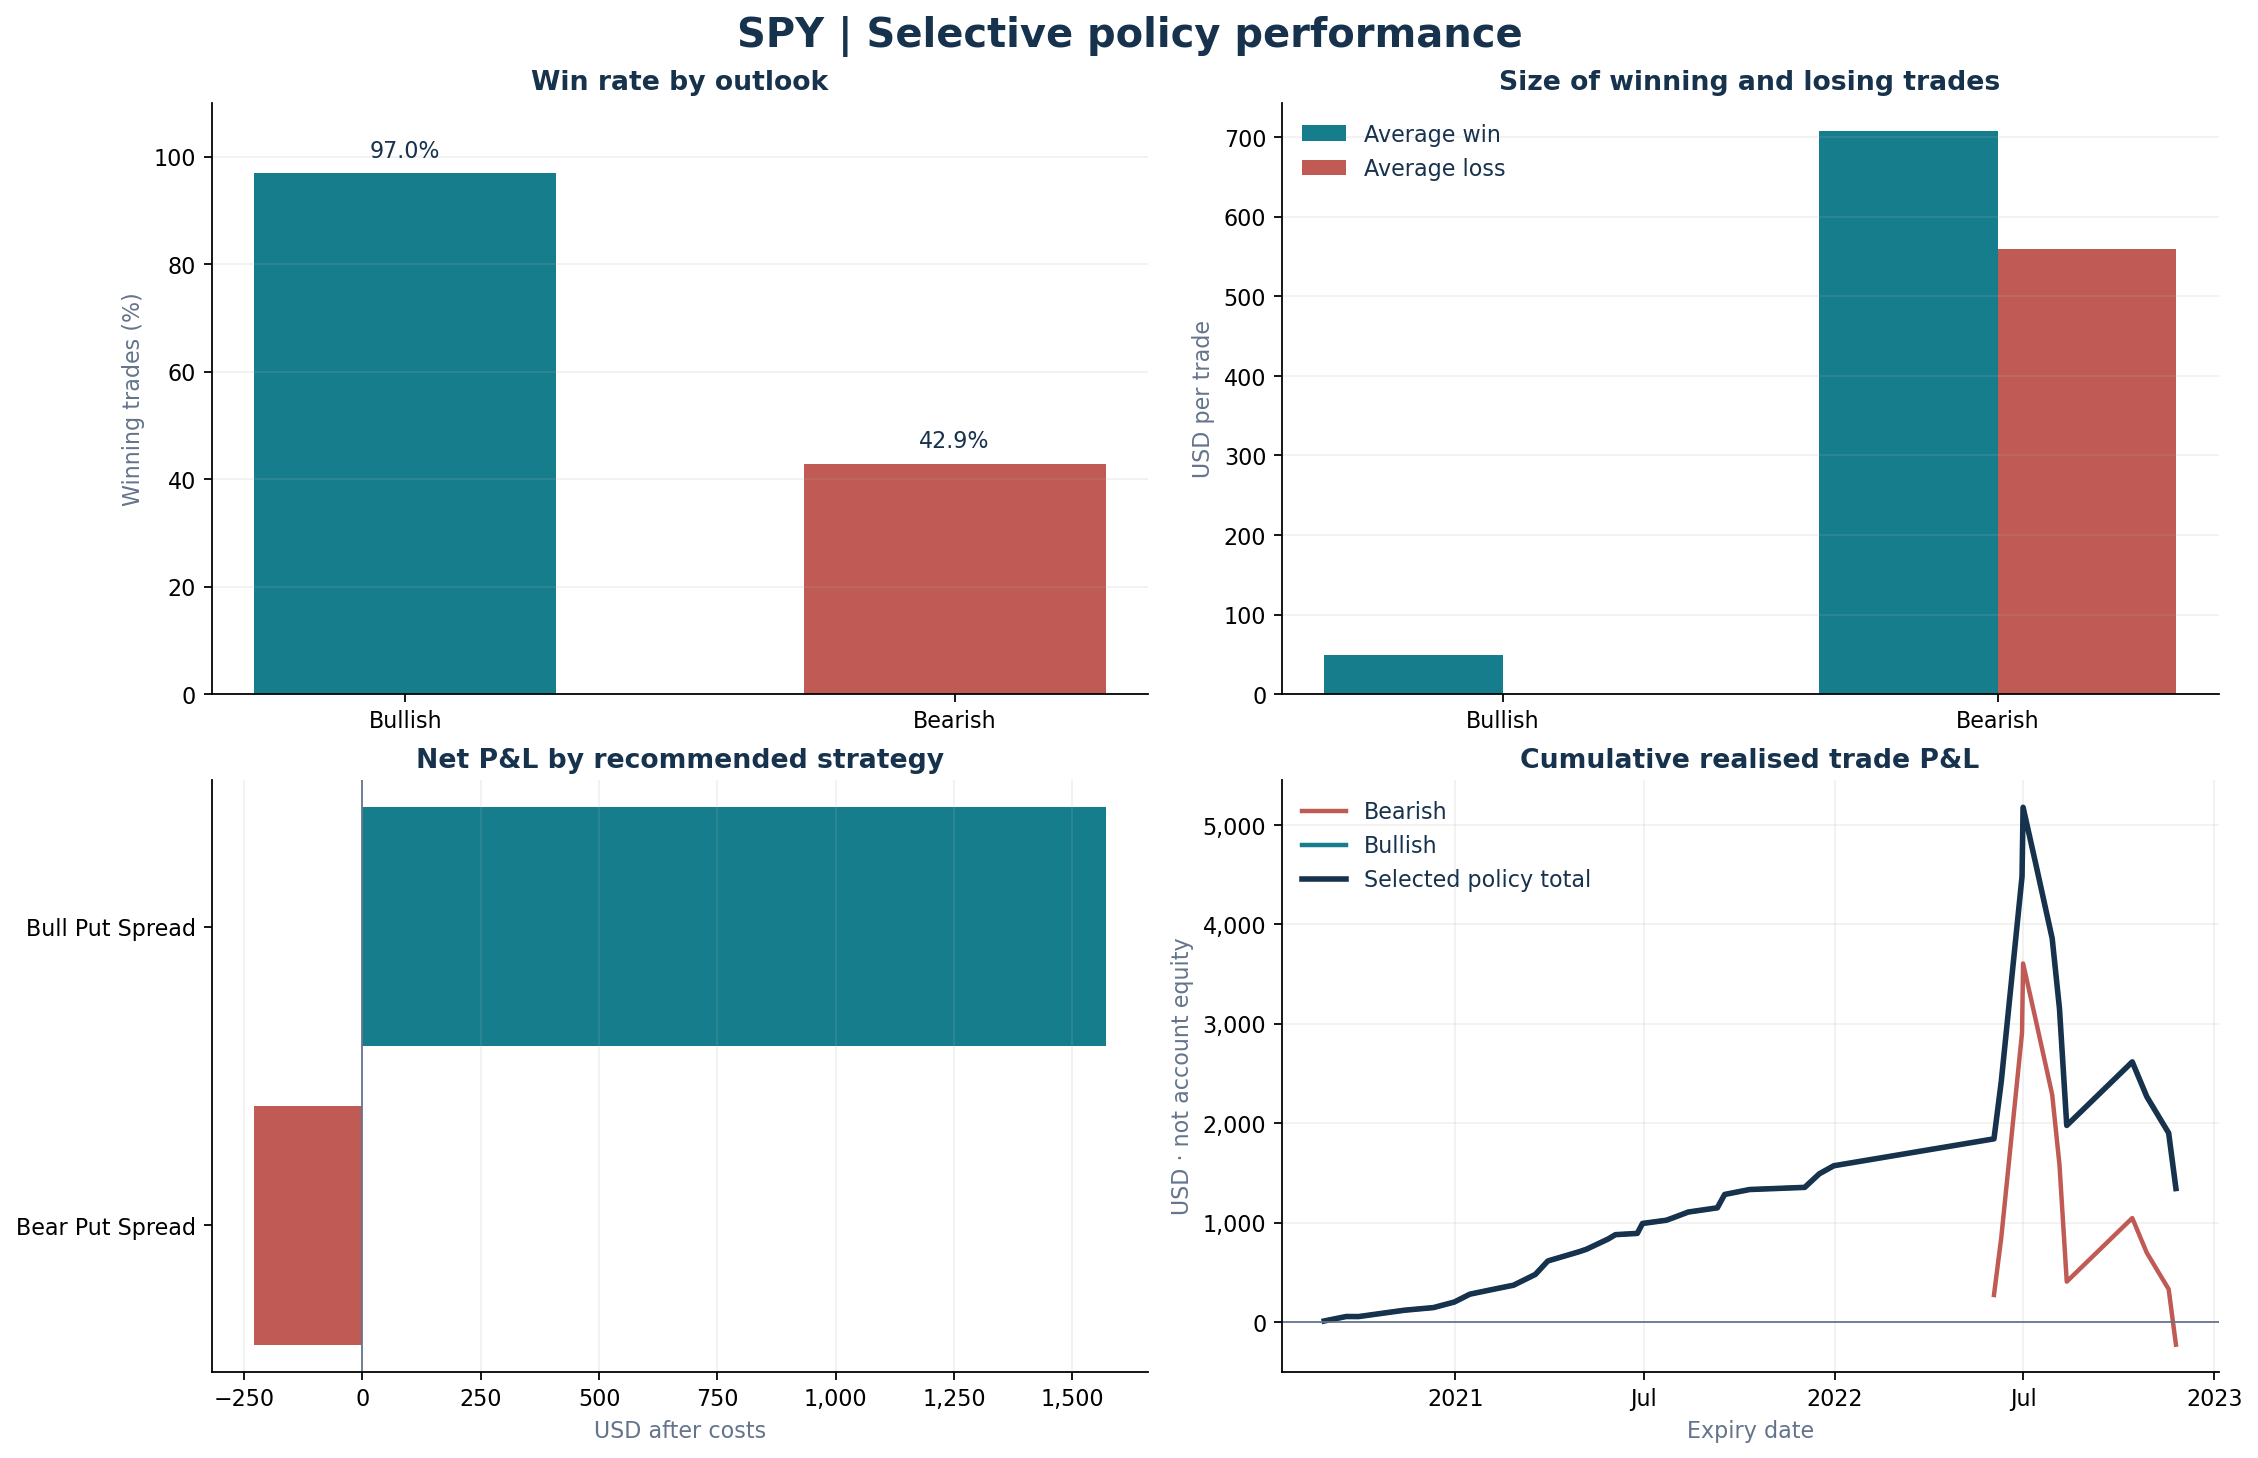

In [48]:
if not trades.empty:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")
    by_outlook = grouped["outlook"].reindex(["bullish", "bearish"]).dropna(subset=["trades"])
    labels = [v.title() for v in by_outlook.index]
    palette = [COLORS[v] for v in by_outlook.index]
    bars = axes[0, 0].bar(labels, by_outlook.win_rate_pct, color=palette, width=0.55)
    axes[0, 0].bar_label(bars, fmt="%.1f%%", padding=5)
    axes[0, 0].set(title="Win rate by outlook", ylabel="Winning trades (%)", ylim=(0, 110))
    axes[0, 0].grid(axis="y")
    x = np.arange(len(labels))
    axes[0, 1].bar(
        x - 0.18, by_outlook.average_win_usd, 0.36, label="Average win", color=COLORS["bullish"]
    )
    axes[0, 1].bar(
        x + 0.18,
        by_outlook.average_loss_usd,
        0.36,
        label="Average loss",
        color=COLORS["bearish"],
    )
    axes[0, 1].set(
        xticks=x,
        xticklabels=labels,
        title="Size of winning and losing trades",
        ylabel="USD per trade",
    )
    axes[0, 1].legend(frameon=False)
    axes[0, 1].grid(axis="y")
    strategy = grouped["strategy_type"].net_pnl_usd.sort_values()
    axes[1, 0].barh(
        [v.replace("_", " ").title() for v in strategy.index],
        strategy.values,
        color=[COLORS["bullish"] if v >= 0 else COLORS["bearish"] for v in strategy],
    )
    axes[1, 0].axvline(0, color=COLORS["muted"], linewidth=0.8)
    axes[1, 0].set(title="Net P&L by recommended strategy", xlabel="USD after costs")
    axes[1, 0].grid(axis="x")
    for outlook, part in trades.groupby("outlook"):
        realised = part.groupby("expiry").net_pnl_usd.sum().sort_index().cumsum()
        axes[1, 1].plot(
            pd.to_datetime(realised.index),
            realised.values,
            label=outlook.title(),
            color=COLORS[outlook],
            linewidth=2,
        )
    policy_total = trades.groupby("expiry").net_pnl_usd.sum().sort_index().cumsum()
    axes[1, 1].plot(
        pd.to_datetime(policy_total.index),
        policy_total.values,
        label="Selected policy total",
        color=COLORS["navy"],
        linewidth=2.5,
    )
    date_locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
    axes[1, 1].xaxis.set_major_locator(date_locator)
    axes[1, 1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
    axes[1, 1].axhline(0, color=COLORS["muted"], linewidth=0.8)
    axes[1, 1].set(
        title="Cumulative realised trade P&L",
        xlabel="Expiry date",
        ylabel="USD · not account equity",
    )
    axes[1, 1].legend(frameon=False)
    axes[1, 1].grid()
    for ax in [axes[0, 1], axes[1, 1]]:
        ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    axes[1, 0].xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    fig.suptitle("SPY | Selective policy performance", fontsize=18, fontweight="bold")
    show_chart(fig, dpi=160, bbox_inches="tight")


### 6.2 Stock price, trade entries and trend verification
The top panel overlays SPY and its **50-session moving average**, with triangles at actual option-entry dates. The middle panel shows percentage distance above or below the moving average. The bottom panel shows the **20-session return**. Circles in the lower panels mark the **decision snapshot**, when the rule is evaluated, before next-session execution.

- **Bullish:** price above its moving average **and** positive 20-session return. Both decision circles must be above zero.
- **Bearish:** price below its moving average **and** negative 20-session return. Both decision circles must be below zero.

Every selected position, including the one with a missing expiry outcome, is checked. The entry_points table includes both indicator values and pass/fail columns. Indicators use the same available exchange-session observations as the trading policy. These checks establish that the trades followed the rule; they do not establish that the rule predicts future prices.


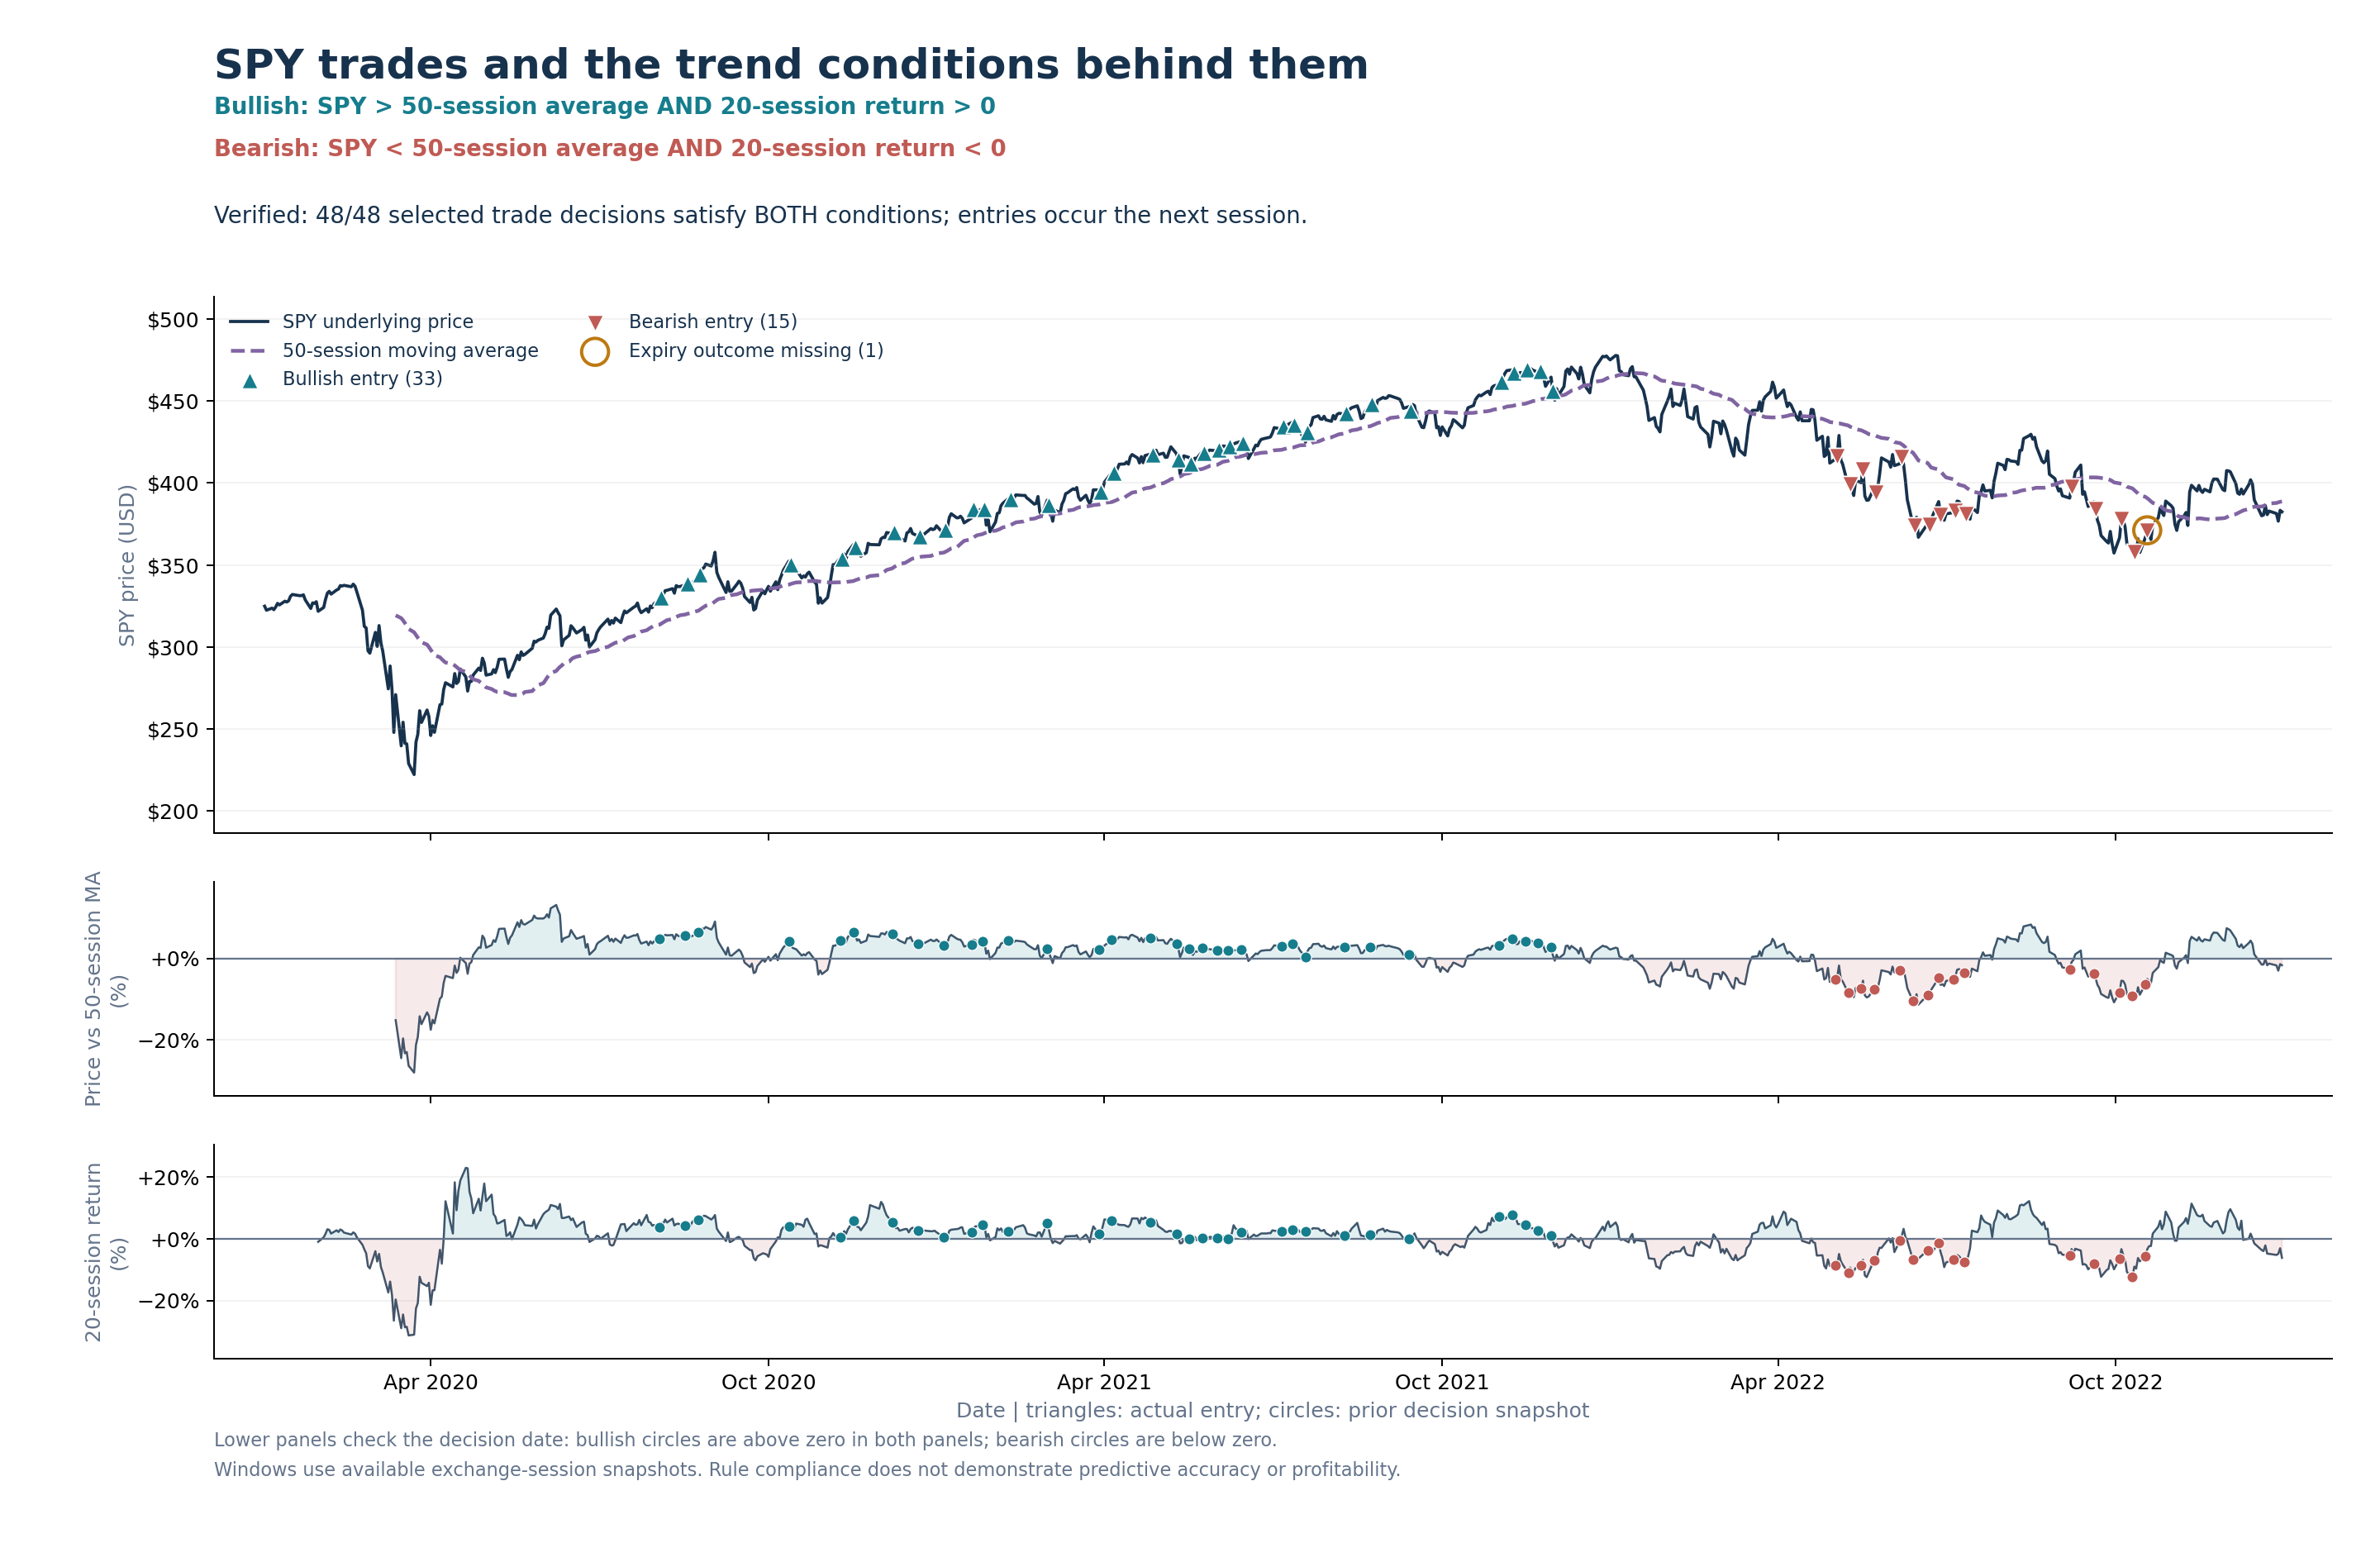

In [50]:
# The trend is tested at the decision snapshot; execution occurs next session.
price_history = closes.sort_index()
trend_average = price_history.rolling(TREND_WINDOW, min_periods=TREND_WINDOW).mean()
momentum_pct = price_history.pct_change(MOMENTUM_WINDOW, fill_method=None) * 100
distance_from_average_pct = (price_history / trend_average - 1) * 100

entry_points = policy_positions[
    [
        "scenario_id",
        "decision_ts",
        "entry_ts",
        "outlook",
        "strategy_type",
        "expiry",
        "net_pnl_usd",
    ]
].copy()
for timestamp, date_column in [("decision_ts", "decision_date"), ("entry_ts", "entry_date")]:
    entry_points[date_column] = (
        pd.to_datetime(entry_points[timestamp], utc=True)
        .dt.tz_convert("America/New_York")
        .dt.strftime("%Y-%m-%d")
    )
entry_points["entry_stock_price"] = entry_points.entry_date.map(price_history)
entry_points["decision_stock_price"] = entry_points.decision_date.map(price_history)
entry_points["decision_moving_average"] = entry_points.decision_date.map(trend_average)
entry_points["decision_distance_from_average_pct"] = entry_points.decision_date.map(
    distance_from_average_pct
)
entry_points["decision_momentum_return_pct"] = entry_points.decision_date.map(momentum_pct)
entry_points["trend_window"] = TREND_WINDOW
entry_points["momentum_window"] = MOMENTUM_WINDOW
entry_points["expiry_outcome_available"] = entry_points.net_pnl_usd.notna()
entry_points["price_condition_passed"] = (
    entry_points.outlook.eq("bullish")
    & entry_points.decision_stock_price.gt(entry_points.decision_moving_average)
) | (
    entry_points.outlook.eq("bearish")
    & entry_points.decision_stock_price.lt(entry_points.decision_moving_average)
)
entry_points["return_condition_passed"] = (
    entry_points.outlook.eq("bullish") & entry_points.decision_momentum_return_pct.gt(0)
) | (entry_points.outlook.eq("bearish") & entry_points.decision_momentum_return_pct.lt(0))
entry_points["both_trend_conditions_passed"] = (
    entry_points.price_condition_passed & entry_points.return_condition_passed
)
entry_points = entry_points.sort_values(["entry_date", "scenario_id"]).reset_index(drop=True)
assert entry_points.entry_stock_price.notna().all(), "An entry date has no underlying snapshot."
assert (
    entry_points.both_trend_conditions_passed.all()
), "A selected trade violates its decision-date trend rule."
assert len(entry_points) == len(policy_positions)

fig, axes = plt.subplots(
    3, 1, figsize=(16, 10.5), sharex=True, gridspec_kw={"height_ratios": [2.5, 1, 1]}
)
fig.subplots_adjust(left=0.09, right=0.98, top=0.81, bottom=0.13, hspace=0.15)
dates = pd.to_datetime(price_history.index)
axes[0].plot(
    dates,
    price_history.values,
    color=COLORS["navy"],
    linewidth=1.5,
    label="SPY underlying price",
    zorder=1,
)
axes[0].plot(
    dates,
    trend_average.values,
    color="#8064A2",
    linewidth=1.8,
    linestyle="--",
    label=f"{TREND_WINDOW}-session moving average",
    zorder=2,
)

for ax, values, label in [
    (axes[1], distance_from_average_pct, f"Price vs {TREND_WINDOW}-session MA"),
    (axes[2], momentum_pct, f"{MOMENTUM_WINDOW}-session return"),
]:
    ax.plot(dates, values.values, color=COLORS["navy"], linewidth=1, alpha=0.8)
    ax.fill_between(
        dates,
        values.values,
        0,
        where=values.values > 0,
        color=COLORS["bullish"],
        alpha=0.12,
        interpolate=True,
    )
    ax.fill_between(
        dates,
        values.values,
        0,
        where=values.values < 0,
        color=COLORS["bearish"],
        alpha=0.12,
        interpolate=True,
    )
    ax.axhline(0, color=COLORS["muted"], linewidth=0.9)
    ax.set_ylabel(label + "\n(%)", fontsize=10)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:+.0f}%"))

for outlook, marker in [("bullish", "^"), ("bearish", "v")]:
    selected = entry_points.loc[entry_points.outlook == outlook]
    axes[0].scatter(
        pd.to_datetime(selected.entry_date),
        selected.entry_stock_price,
        marker=marker,
        s=65,
        color=COLORS[outlook],
        edgecolors="white",
        linewidths=0.7,
        zorder=4,
        label=f"{outlook.title()} entry ({len(selected)})",
    )
    for ax, field in [
        (axes[1], "decision_distance_from_average_pct"),
        (axes[2], "decision_momentum_return_pct"),
    ]:
        ax.scatter(
            pd.to_datetime(selected.decision_date),
            selected[field],
            marker="o",
            s=28,
            color=COLORS[outlook],
            edgecolors="white",
            linewidths=0.5,
            zorder=4,
        )

unresolved_entries = entry_points.loc[~entry_points.expiry_outcome_available]
if not unresolved_entries.empty:
    axes[0].scatter(
        pd.to_datetime(unresolved_entries.entry_date),
        unresolved_entries.entry_stock_price,
        marker="o",
        s=170,
        facecolors="none",
        edgecolors="#BD7A12",
        linewidths=1.6,
        zorder=5,
        label=f"Expiry outcome missing ({len(unresolved_entries)})",
    )

axes[0].set_ylabel("SPY price (USD)")
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
axes[0].legend(loc="upper left", frameon=False, fontsize=9, ncol=2)
axes[2].set_xlabel("Date | triangles: actual entry; circles: prior decision snapshot")
axes[2].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for ax in axes:
    ax.grid(axis="y", alpha=0.16)
    ax.margins(x=0.025, y=0.14)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "SPY trades and the trend conditions behind them",
    x=0.09,
    ha="left",
    y=0.97,
    fontsize=20,
    fontweight="bold",
    color=COLORS["navy"],
)
fig.text(
    0.09,
    0.927,
    f"Bullish: SPY > {TREND_WINDOW}-session average AND {MOMENTUM_WINDOW}-session return > 0",
    fontsize=11,
    fontweight="bold",
    color=COLORS["bullish"],
)
fig.text(
    0.09,
    0.900,
    f"Bearish: SPY < {TREND_WINDOW}-session average AND {MOMENTUM_WINDOW}-session return < 0",
    fontsize=11,
    fontweight="bold",
    color=COLORS["bearish"],
)
fig.text(
    0.09,
    0.857,
    f"Verified: {int(entry_points.both_trend_conditions_passed.sum())}/{len(entry_points)} "
    "selected trade decisions satisfy BOTH conditions; entries occur the next session.",
    fontsize=11,
    color=COLORS["navy"],
)
fig.text(
    0.09,
    0.055,
    "Lower panels check the decision date: bullish circles are above zero in both panels; bearish circles are below zero.\n"
    "Windows use available exchange-session snapshots. Rule compliance does not demonstrate predictive accuracy or profitability.",
    fontsize=9,
    color=COLORS["muted"],
    linespacing=1.7,
)
show_chart(fig, dpi=180, facecolor="white")


### 6.3 · Results by year and strategy
Years below refer to **expiry year**. Trade counts are shown to help judge how much evidence supports each result.

In [52]:
if not trades.empty:
    by_year_outlook = grouped_performance(trades, ["expiry_year", "outlook"])
    fields = [
        "trades",
        "win_rate_pct",
        "average_pnl_per_trade_usd",
        "net_pnl_usd",
        "profit_factor",
    ]
    show_table(by_year_outlook[fields].reset_index())
    show_table(grouped["strategy_type"][fields].reset_index())


expiry_year,outlook,trades,win_rate_pct,average_pnl_per_trade_usd,net_pnl_usd,profit_factor
"2,020.00",bullish,6.00,83.33,33.31,199.84,556.11
"2,021.00",bullish,27.00,100.00,50.79,"1,371.28",inf
"2,022.00",bearish,14.00,42.86,-16.36,-229.04,0.95


strategy_type,trades,win_rate_pct,average_pnl_per_trade_usd,net_pnl_usd,profit_factor
bear_put_spread,14.00,42.86,-16.36,-229.04,0.95
bull_put_spread,33.00,96.97,47.61,"1,571.12","4,365.22"


### 6.4 · Trade log and skipped scenarios
Preview the first 15 completed trades. The trades DataFrame contains the full log and option legs.

In [54]:
show_table(
    trades[
        [
            "decision_ts",
            "outlook",
            "strategy_type",
            "expiry",
            "long_strike",
            "short_strike",
            "net_pnl_usd",
            "outcome",
        ]
    ].head(15)
)
if not skips.empty:
    show_table(
        skips.groupby("reason").size().rename("Skipped scenarios").reset_index(), decimals=0
    )


decision_ts,outlook,strategy_type,expiry,long_strike,short_strike,net_pnl_usd,outcome
2020-08-03 20:15:00+00:00,bullish,bull_put_spread,2020-08-28,280.00,286.00,9.64,win
2020-08-17 20:15:00+00:00,bullish,bull_put_spread,2020-09-18,307.00,313.00,44.64,win
2020-08-24 20:15:00+00:00,bullish,bull_put_spread,2020-09-30,225.00,230.00,-0.36,loss
2020-10-12 20:15:00+00:00,bullish,bull_put_spread,2020-11-13,312.50,320.00,63.64,win
2020-11-09 21:15:00+00:00,bullish,bull_put_spread,2020-12-31,300.00,308.00,55.64,win
2020-11-16 21:15:00+00:00,bullish,bull_put_spread,2020-12-11,337.00,340.00,26.64,win
2020-12-07 21:15:00+00:00,bullish,bull_put_spread,2021-01-15,335.00,343.00,71.64,win
2020-12-21 21:15:00+00:00,bullish,bull_put_spread,2021-01-15,319.00,322.00,7.64,win
2021-01-04 21:15:00+00:00,bullish,bull_put_spread,2021-02-05,337.50,342.50,45.64,win
2021-01-19 21:15:00+00:00,bullish,bull_put_spread,2021-02-26,335.00,344.00,44.64,win


reason,Skipped scenarios
insufficient_settled_same_regime_evidence,41
invalid_bid_ask,4
invalid_spread_entry_value,2
missing_expiry_outcome,1
neutral_or_insufficient_trend,28
nonpositive_settled_strategy_expectancy,7
spread_too_wide,11
trend_not_aligned,108
unit_risk_exceeds_trade_limit,21


### 6.5 · Compare shadow recommendations and selected trades
Compare both outlooks with the policy that selects at most one outlook per date. All comparisons are retrospective.


In [56]:
def decision_period(frame):
    """Assign development and evaluation periods by decision date."""
    dates = decision_dates(frame)
    return pd.Series(
        np.select(
            [dates < VALIDATION_START, dates < RETROSPECTIVE_TEST_START],
            ["development", "validation"],
            default="retrospective_test",
        ),
        index=frame.index,
    )


In [57]:
variants = {"original_both_outlooks": shadow_trades.copy(), "walkforward_policy": trades.copy()}
comparison_rows = []
for name, frame in variants.items():
    frame["evaluation_period"] = decision_period(frame)
    for period in ["all", "development", "validation", "retrospective_test"]:
        part = frame if period == "all" else frame.loc[frame.evaluation_period == period]
        comparison_rows.append(dict(variant=name, period=period, **performance(part).to_dict()))
comparison = pd.DataFrame(comparison_rows)
fields = [
    "variant",
    "period",
    "trades",
    "win_rate_pct",
    "net_pnl_usd",
    "profit_factor",
    "average_return_on_risk_pct",
]
show_table(comparison[fields])


variant,period,trades,win_rate_pct,net_pnl_usd,profit_factor,average_return_on_risk_pct
original_both_outlooks,all,245.00,64.49,"-6,513.08",0.82,-5.87
original_both_outlooks,development,60.00,65.00,"-4,498.60",0.46,-21.97
original_both_outlooks,validation,103.00,62.14,-788.36,0.92,-11.47
original_both_outlooks,retrospective_test,82.00,67.07,"-1,226.12",0.93,12.93
walkforward_policy,all,47.00,80.85,"1,342.08",1.30,9.65
walkforward_policy,development,8.00,87.50,279.12,776.33,6.07
walkforward_policy,validation,25.00,100.00,"1,292.00",inf,8.29
walkforward_policy,retrospective_test,14.00,42.86,-229.04,0.95,14.15


### 6.6 Period completeness and available outcomes


In [59]:
maturity_rows = []
for boundary in [VALIDATION_START, RETROSPECTIVE_TEST_START]:
    earlier = decision_dates(shadow_trades) < boundary
    settled = shadow_trades.expiry < boundary
    maturity_rows.append(
        dict(
            boundary=boundary,
            earlier_shadow_decisions=int(earlier.sum()),
            available_settled_labels=int((earlier & settled).sum()),
            future_expiry_labels_excluded=int((earlier & ~settled).sum()),
        )
    )
maturity_audit = pd.DataFrame(maturity_rows)

period_counts = []
for period in ["development", "validation", "retrospective_test"]:
    positions = policy_positions.loc[decision_period(policy_positions) == period]
    excluded = skips.loc[decision_period(skips) == period]
    period_counts.append(
        dict(
            period=period,
            entered_positions=len(positions),
            settled_trades=int(positions.net_pnl_usd.notna().sum()),
            unresolved_entries=int(positions.net_pnl_usd.isna().sum()),
            skipped_or_unresolved_scenarios=len(excluded),
        )
    )
policy_period_counts = pd.DataFrame(period_counts)
print(
    "The shadow variant pools two conditional outlooks; the policy selects at most one per date."
)
print(
    "Compare trade counts and return on risk alongside total dollars. Fewer trades are an intentional policy change."
)
print(
    "All results are retrospective. Positive aggregate P&L does not imply every period is profitable."
)


The shadow variant pools two conditional outlooks; the policy selects at most one per date.
Compare trade counts and return on risk alongside total dollars. Fewer trades are an intentional policy change.
All results are retrospective. Positive aggregate P&L does not imply every period is profitable.


<a id="validation"></a>
## 7 · Validate results
Reconstruct trade cash flows independently, then verify timing, maximum-loss bounds and that every scheduled scenario is accounted for.

### 7.1 Independent payoff and completeness checks


In [62]:
# Independent cash-flow reconstruction and completeness checks.
for _, trade in trades.iterrows():
    legs = json.loads(trade.legs_json)
    entry_cash = -sum(leg["quantity"] * leg["multiplier"] * leg["fill_price"] for leg in legs)
    terminal_cash = sum(
        leg["quantity"]
        * leg["multiplier"]
        * max(
            (trade.expiry_stock_price - leg["strike"])
            * (1 if leg["option_type"] == "call" else -1),
            0,
        )
        for leg in legs
    )
    assert np.isclose(entry_cash + terminal_cash - trade.costs_usd, trade.net_pnl_usd)
    assert trade.net_pnl_usd >= -trade.maximum_risk_usd - 1e-7
    assert pd.Timestamp(trade.entry_ts) > pd.Timestamp(trade.decision_ts)
assert not trades.scenario_id.duplicated().any()
assert not set(trades.scenario_id).intersection(set(skips.scenario_id))
assert len(trades) + len(skips) == len(tasks)
print(
    f"Passed payoff, timing, risk-bound and completeness checks for {len(trades)} trades and {len(skips)} skips."
)


Passed payoff, timing, risk-bound and completeness checks for 47 trades and 223 skips.


### 7.2 Additional results


In [64]:
show_table(overall.reset_index(names="metric"))
show_table(maturity_audit)
show_table(policy_period_counts)


metric,value
trades,47.00
wins,38.00
losses,9.00
breakevens,0.00
win_rate_pct,80.85
average_win_usd,153.09
average_loss_usd,497.25
gross_winning_pnl_usd,"5,817.32"
gross_losing_pnl_usd,"4,475.24"
net_pnl_usd,"1,342.08"


boundary,earlier_shadow_decisions,available_settled_labels,future_expiry_labels_excluded
2021-01-01,60.00,54.00,6.00
2022-01-01,163.00,157.00,6.00


period,entered_positions,settled_trades,unresolved_entries,skipped_or_unresolved_scenarios
development,8.00,8.00,0.00,72.00
validation,25.00,25.00,0.00,79.00
retrospective_test,15.00,14.00,1.00,72.00


<a id="assumptions"></a>
## 8 · Assumptions and interpretation

| Area | Treatment |
|---|---|
| Recommendation | Project source commit `f73c52ae75cf1905ce8323d8a82b5e43eec828e9`; primary GA seed 42. No rule-only comparison. |
| Missing open interest | Remove the OI threshold and weight; use option volume and spread quality. Missing volume retains the original project's lowest-input treatment. |
| Underlying history | Earlier observed `UNDERLYING_LAST` snapshots only. Stock OHLC/volume and ATR remain missing. SMA200 is unavailable until sufficient history exists and is not used for selection. |
| Expiry outcome | Dataset snapshot is the default price proxy. Provide `OFFICIAL_EXPIRY_PRICES_CSV` for official unadjusted closes. Missing official dates are skipped. |
| Assignment | No early exercise, assignment or share delivery. SPY dividends can make this simplification material. |
| Data quality | Holiday records excluded using the exchange calendar. Missing entry or expiry data is logged. Timestamps do not guarantee fresh quotes or fills. |
| Capital and risk | One contract per leg; trades may overlap. Results are trade-level P&L, not account return or maximum drawdown. |
| Evaluation | Shadow recommendations cover both outlooks; the revised policy chooses an outlook from past trend observations. Weekly outcomes are not independent observations. |

**Read win rate alongside average win, average loss and net P&L.** Many small wins can be outweighed by fewer large losses.

### References
- [Uploaded Kaggle SPY dataset](https://www.kaggle.com/datasets/kylegraupe/spy-daily-eod-options-quotes-2020-2022)
- [optionsDX field definitions](https://www.optionsdx.com/option-chain-field-definitions/)

### Revision: chronological selection policy
The original candidate scoring and GA are restored. The model-return threshold was rejected after it shifted selection toward low-probability trades. The policy now selects a trend-aligned outlook and demands positive, settled evidence for that strategy in the same observed regime. Shadow outcomes are legitimate paper observations only after expiry; skipped live trades may still contribute subsequently settled shadow evidence. Every accepted decision records its evidence count and latest available expiry.

Missing expiry outcomes never enter the evidence set. Valid selected entries with missing outcomes still reserve risk through expiry and are reported separately. At most one outlook is selected per decision date, with one contract per leg. Positions over the risk limit are skipped, not scaled. A cap on overlapping maximum losses is not a complete account, margin, assignment or mark-to-market model.

The policy was developed after reviewing this dataset; both an unconditioned-history gate and a same-regime gate were inspected during revision. This creates research-selection bias even though each replay decision uses past information only. No future profitability is implied. Obtain new dates before making an out-of-sample performance claim.

Shadow results, selected positions, decision audits, observed regimes, comparisons and metrics remain available as DataFrames in the notebook. Charts are displayed inline.
